# Selection-Adjusted False Discovery across Searched Trials

For one trial, the posterior probability that a reported discovery came from the null is:

$$
\operatorname{FDR}_1
=\frac{\alpha\pi_0}
{\alpha\pi_0+(1-\beta)(1-\pi_0)}.
$$

Here, $\alpha$ is the one-trial Type I error probability, $\beta$ is the one-trial Type II error probability, $\pi_0$ is the prior probability that the trial is null, and $\operatorname{FDR}_1$ is the null probability conditional on observing a discovery in that single trial.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from dataclasses import FrozenInstanceError, fields
import inspect
import math
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ndtr
from scipy.stats import norm
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]


from RiskLabAI.causal_factor_analysis import AllocationMisspecificationDiagnostics, FDRComparisonEvidence, FDRNonIdentificationWitness, GaussianSearchAdjustedFDR, GaussianTrialMixture, MaxSelectionFamilyErrors, SelectionLevelProbabilityEvidence, allocation_misspecification_diagnostics, compare_single_and_family_fdr, conditional_upper_tail_probability, family_level_false_discovery_rate, fdr_nonidentification_witness, gaussian_max_selection_cdf, gaussian_max_selection_log_density, gaussian_max_selection_log_likelihood, gaussian_search_adjusted_false_discovery_rate, gaussian_trial_mixture_cdf, max_selection_family_errors, max_selection_null_probability, maximum_mixture_cdf, minimum_variance_factor_weights, single_trial_false_discovery_rate

FIGURES = ROOT / "outputs" / "figures" / "08_search_adjusted_portfolios"
TABLES = ROOT / "outputs" / "tables" / "08_search_adjusted_portfolios"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float)

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def contract_result(name, action, expected):
    try:
        action()
        return {"Check": name, "Expected result": expected, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        return {"Check": name, "Expected result": expected, "Observed result": type(error).__name__, "Passed": type(error).__name__ == expected}

def kkt_oracle(covariance, exposures, targets):
    asset_count, factor_count = exposures.shape
    system = np.block([[2.0 * covariance, exposures], [exposures.T, np.zeros((factor_count, factor_count))]])
    right_side = np.concatenate([np.zeros(asset_count), targets])
    solution = np.linalg.solve(system, right_side)
    return solution[:asset_count], solution[asset_count:]

def portfolio_variance(covariance, weights):
    return float(weights @ covariance @ weights)

def normal_density(value, scale=1.0):
    return math.exp(-0.5 * (value / scale) ** 2) / (math.sqrt(2.0 * math.pi) * scale)

case_b_alpha = 0.024997895148220373
case_b_beta = 0.9515427737332771
case_b_null = 0.15
case_b_fdr = single_trial_false_discovery_rate(case_b_alpha, case_b_beta, case_b_null)
bayes_table = pd.DataFrame([
    {"Latent state": "Null", "Decision": "Discovery", "Joint probability": case_b_null * case_b_alpha, "Included in discoveries": True, "False discovery": True},
    {"Latent state": "Null", "Decision": "No discovery", "Joint probability": case_b_null * (1.0 - case_b_alpha), "Included in discoveries": False, "False discovery": False},
    {"Latent state": "Alternative", "Decision": "Discovery", "Joint probability": (1.0 - case_b_null) * (1.0 - case_b_beta), "Included in discoveries": True, "False discovery": False},
    {"Latent state": "Alternative", "Decision": "No discovery", "Joint probability": (1.0 - case_b_null) * case_b_beta, "Included in discoveries": False, "False discovery": False},
])
save_table(bayes_table, "fdr_single_trial_bayes", "Four-state probability table for the published one-trial case.", "tab:chapter27-fdr-single-bayes")
display(bayes_table)

boundary_cases = [(0.0, 0.2, 0.7), (0.2, 1.0, 0.7), (0.4, 0.6, 0.5), (1.0, 0.0, 0.0), (1.0, 1.0, 1.0)]
boundary_rows = []
for alpha, beta, prior in boundary_cases:
    boundary_rows.append({"Type I error": alpha, "Type II error": beta, "Trial null probability": prior, "Single-trial false discovery rate": single_trial_false_discovery_rate(alpha, beta, prior)})
boundary_table = pd.DataFrame(boundary_rows)
save_table(boundary_table, "fdr_single_trial_boundaries", "Boundary identities for the one-trial false discovery rate.", "tab:chapter27-fdr-single-boundaries")
display(boundary_table)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


,Latent state,Decision,Joint probability,Included in discoveries,False discovery
0,Null,Discovery,0.00375,True,True
1,Null,No discovery,0.14625,False,False
2,Alternative,Discovery,0.041189,True,False
3,Alternative,No discovery,0.808811,False,False


,Type I error,Type II error,Trial null probability,Single-trial false discovery rate
0,0,0.2,0.7,0
1,0.2,1,0.7,1
2,0.4,0.6,0.5,0.5
3,1,0,0,0
4,1,1,1,1


## How a searched family changes error probabilities

For a searched family of $K$ independent trials, the family null probability and family false discovery rate are:

$$
\pi_F=\pi_0^K,
\qquad
\operatorname{FDR}_F
=\frac{\alpha_F\pi_F}
{\alpha_F\pi_F+(1-\beta_F)(1-\pi_F)}.
$$

Here, $K$ is the number of searched trials, $\pi_F$ is the probability that all $K$ trials are null, $\alpha_F$ is the family Type I error probability, $\beta_F$ is the family Type II error probability conditional on a family containing at least one alternative, and $\operatorname{FDR}_F$ is the family-level posterior null probability after a discovery.

,Case,Trials,Trial null probability,Family null probability,Type I error,Type II error,False discovery rate
0,One reported trial,1,0.15,0.15,0.024998,0.951543,0.083441
1,Published search case,10,0.95,0.598737,0.223654,0.753196,0.57486
2,Sensitivity case,5,0.9,0.59049,0.226219,0.724577,0.542196


,Trials,Family null probability,Family Type I error,Family Type II error,Family false discovery rate
0,1,0.95,0.024998,0.951543,0.907421
1,2,0.9025,0.049371,0.927184,0.862563
2,5,0.773781,0.118895,0.857733,0.740836
3,10,0.598737,0.223654,0.753196,0.57486
4,20,0.358486,0.397286,0.580365,0.346
5,50,0.076945,0.717981,0.264172,0.075219


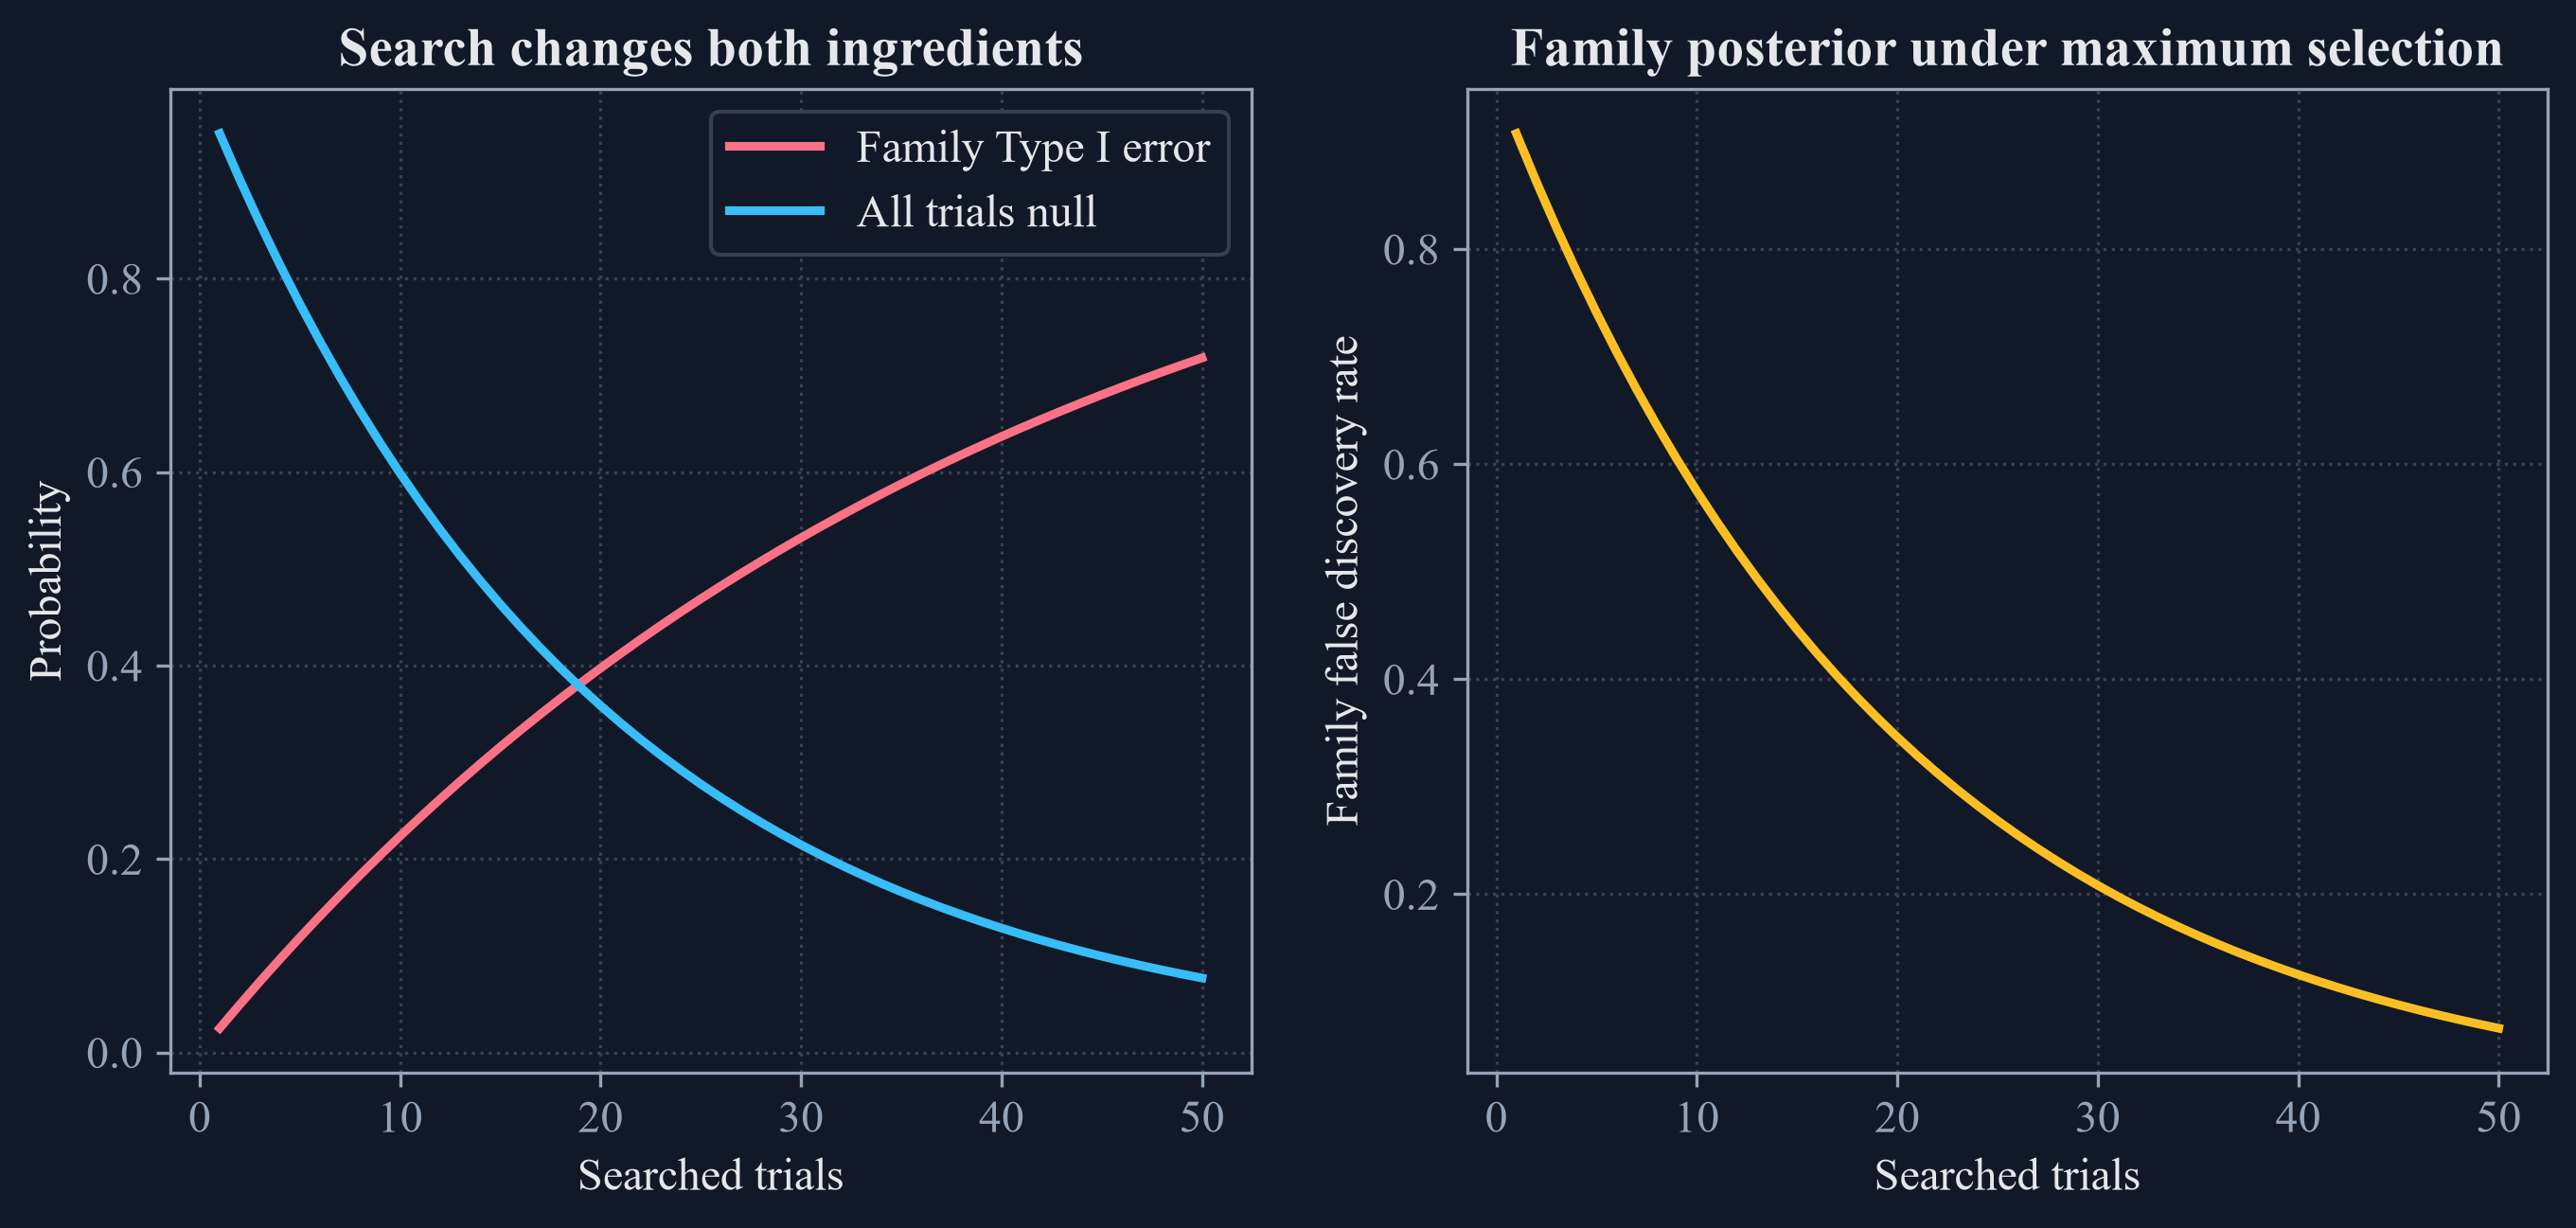

In [2]:
case_a_null = 0.95
case_a_trials = 10
case_a_errors = max_selection_family_errors(case_b_alpha, case_b_beta, case_a_null, case_a_trials)
case_a_fdr = family_level_false_discovery_rate(case_a_errors.family_type_i_error, case_a_errors.family_type_ii_error, case_a_null, case_a_trials)
sensitivity_errors = max_selection_family_errors(0.05, 0.90, 0.90, 5)
sensitivity_fdr = family_level_false_discovery_rate(sensitivity_errors.family_type_i_error, sensitivity_errors.family_type_ii_error, 0.90, 5)
published_table = pd.DataFrame([
    {"Case": "One reported trial", "Trials": 1, "Trial null probability": case_b_null, "Family null probability": case_b_null, "Type I error": case_b_alpha, "Type II error": case_b_beta, "False discovery rate": case_b_fdr},
    {"Case": "Published search case", "Trials": case_a_trials, "Trial null probability": case_a_null, "Family null probability": case_a_errors.family_null_probability, "Type I error": case_a_errors.family_type_i_error, "Type II error": case_a_errors.family_type_ii_error, "False discovery rate": case_a_fdr},
    {"Case": "Sensitivity case", "Trials": 5, "Trial null probability": 0.90, "Family null probability": sensitivity_errors.family_null_probability, "Type I error": sensitivity_errors.family_type_i_error, "Type II error": sensitivity_errors.family_type_ii_error, "False discovery rate": sensitivity_fdr},
])
save_table(published_table, "fdr_published_cases", "Published and sensitivity false discovery calculations.", "tab:chapter27-fdr-published-cases")
display(published_table)

search_counts = np.arange(1, 51)
search_rows = []
for trials in search_counts:
    errors = max_selection_family_errors(case_b_alpha, case_b_beta, case_a_null, int(trials))
    family_fdr = family_level_false_discovery_rate(errors.family_type_i_error, errors.family_type_ii_error, case_a_null, int(trials))
    search_rows.append({"Trials": int(trials), "Family null probability": errors.family_null_probability, "Family Type I error": errors.family_type_i_error, "Family Type II error": errors.family_type_ii_error, "Family false discovery rate": family_fdr})
search_frame = pd.DataFrame(search_rows)
search_table = search_frame[search_frame["Trials"].isin([1, 2, 5, 10, 20, 50])].reset_index(drop=True)
save_table(search_table, "fdr_search_count_grid", "Family probabilities as the number of searched trials changes.", "tab:chapter27-fdr-search-count")
display(search_table)

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5))
axes[0].plot(search_frame["Trials"], search_frame["Family Type I error"], color=palette["rose"], linewidth=2.2, label="Family Type I error")
axes[0].plot(search_frame["Trials"], search_frame["Family null probability"], color=palette["cyan"], linewidth=2.2, label="All trials null")
axes[0].set_xlabel("Searched trials")
axes[0].set_ylabel("Probability")
axes[0].set_title("Search changes both ingredients")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(search_frame["Trials"], search_frame["Family false discovery rate"], color=palette["amber"], linewidth=2.2)
axes[1].set_xlabel("Searched trials")
axes[1].set_ylabel("Family false discovery rate")
axes[1].set_title("Family posterior under maximum selection")
axes[1].grid(True)
save_figure(figure, "fdr_search_count_paths")

## Maximum Selection Uses the Maximum of Trial Mixtures

The distribution of the selected maximum and its family error probabilities are:

$$
H_K(z)=\{\pi_0F_0(z)+(1-\pi_0)F_1(z)\}^{K},
\qquad
\alpha_F=1-(1-\alpha)^K,
\qquad
\beta_F=\frac{[\pi_0(1-\alpha)+(1-\pi_0)\beta]^K-[\pi_0(1-\alpha)]^K}{1-\pi_0^K}.
$$

Here, $F_0$ and $F_1$ are the one-trial null and alternative cumulative distributions, $H_K$ is the cumulative distribution of the maximum across $K$ trial mixtures, and $\alpha$, $\beta$, $\pi_0$, $\alpha_F$, and $\beta_F$ have their one-trial and family meanings defined above.

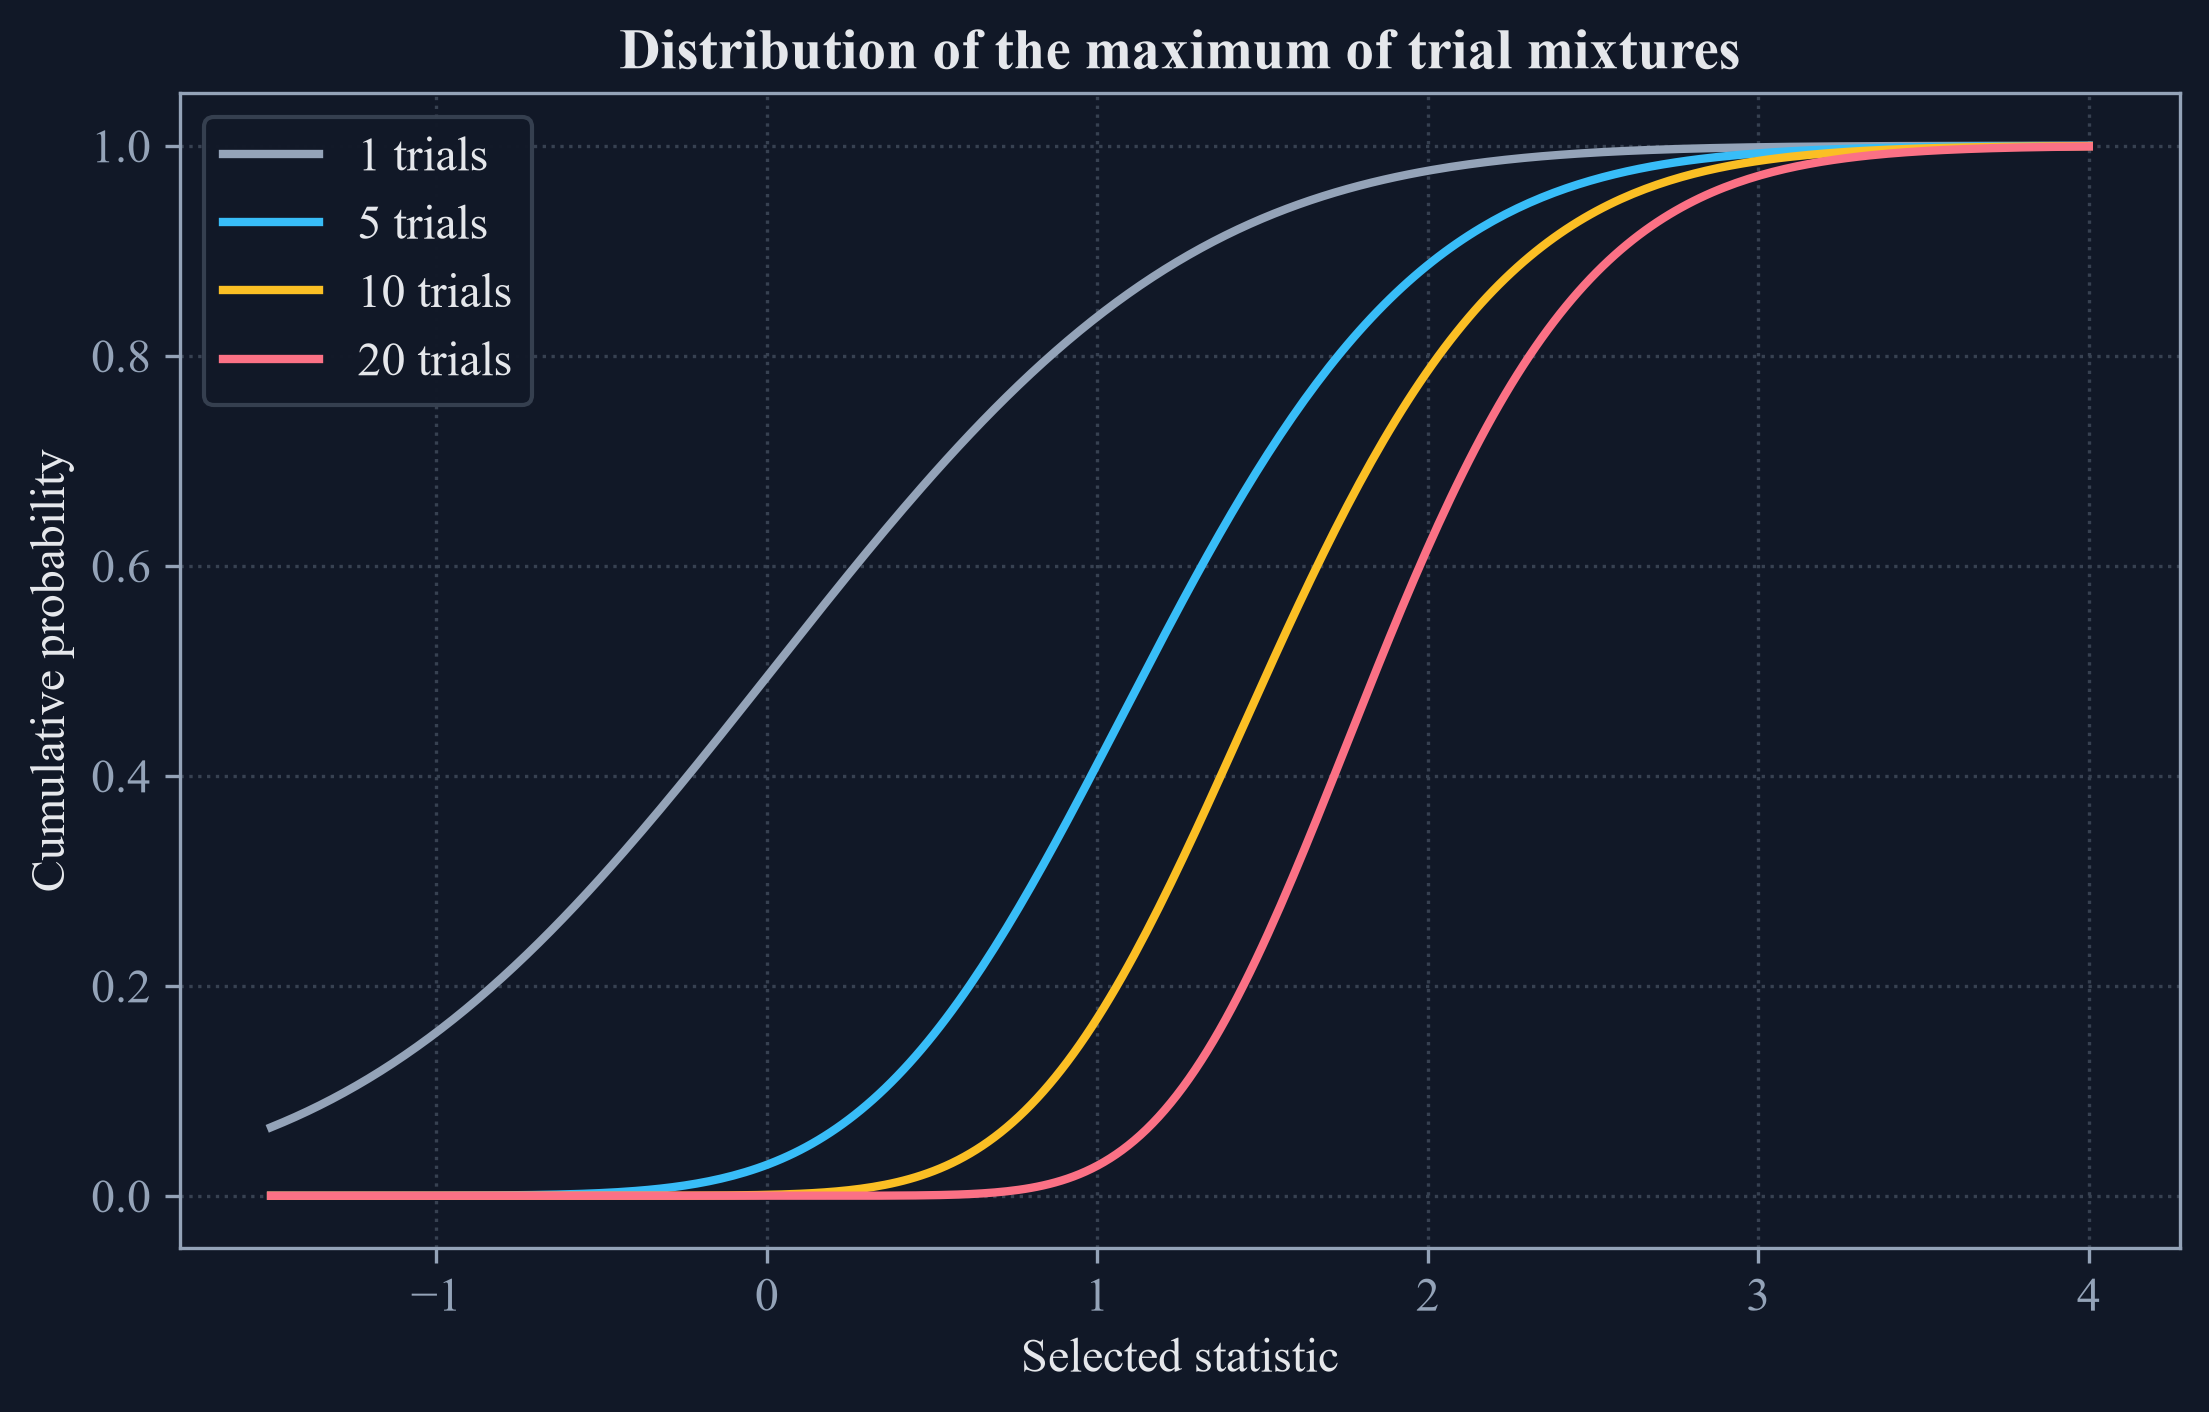

,Threshold,Trial Type I error,Trial Type II error,Family Type I error,Family Type II error,Family false discovery rate
0,1.64,0.050503,0.909877,0.404423,0.564899,0.581051
1,1.96,0.024998,0.951543,0.223654,0.753196,0.57486
2,2.33,0.009903,0.978822,0.094732,0.892455,0.567915
3,3.09,0.001001,0.997365,0.009963,0.988019,0.553735


,Threshold,Analytical cumulative probability,Generated cumulative probability,Absolute difference,Two-standard-error allowance
0,-0.5,0.000007,0,0.000007,0.000016
1,0,0.000867,0.00096,0.000093,0.000186
2,1,0.169116,0.16839,0.000726,0.002371
3,1.96,0.767057,0.76782,0.000763,0.002673
4,3,0.985537,0.98509,0.000447,0.000755


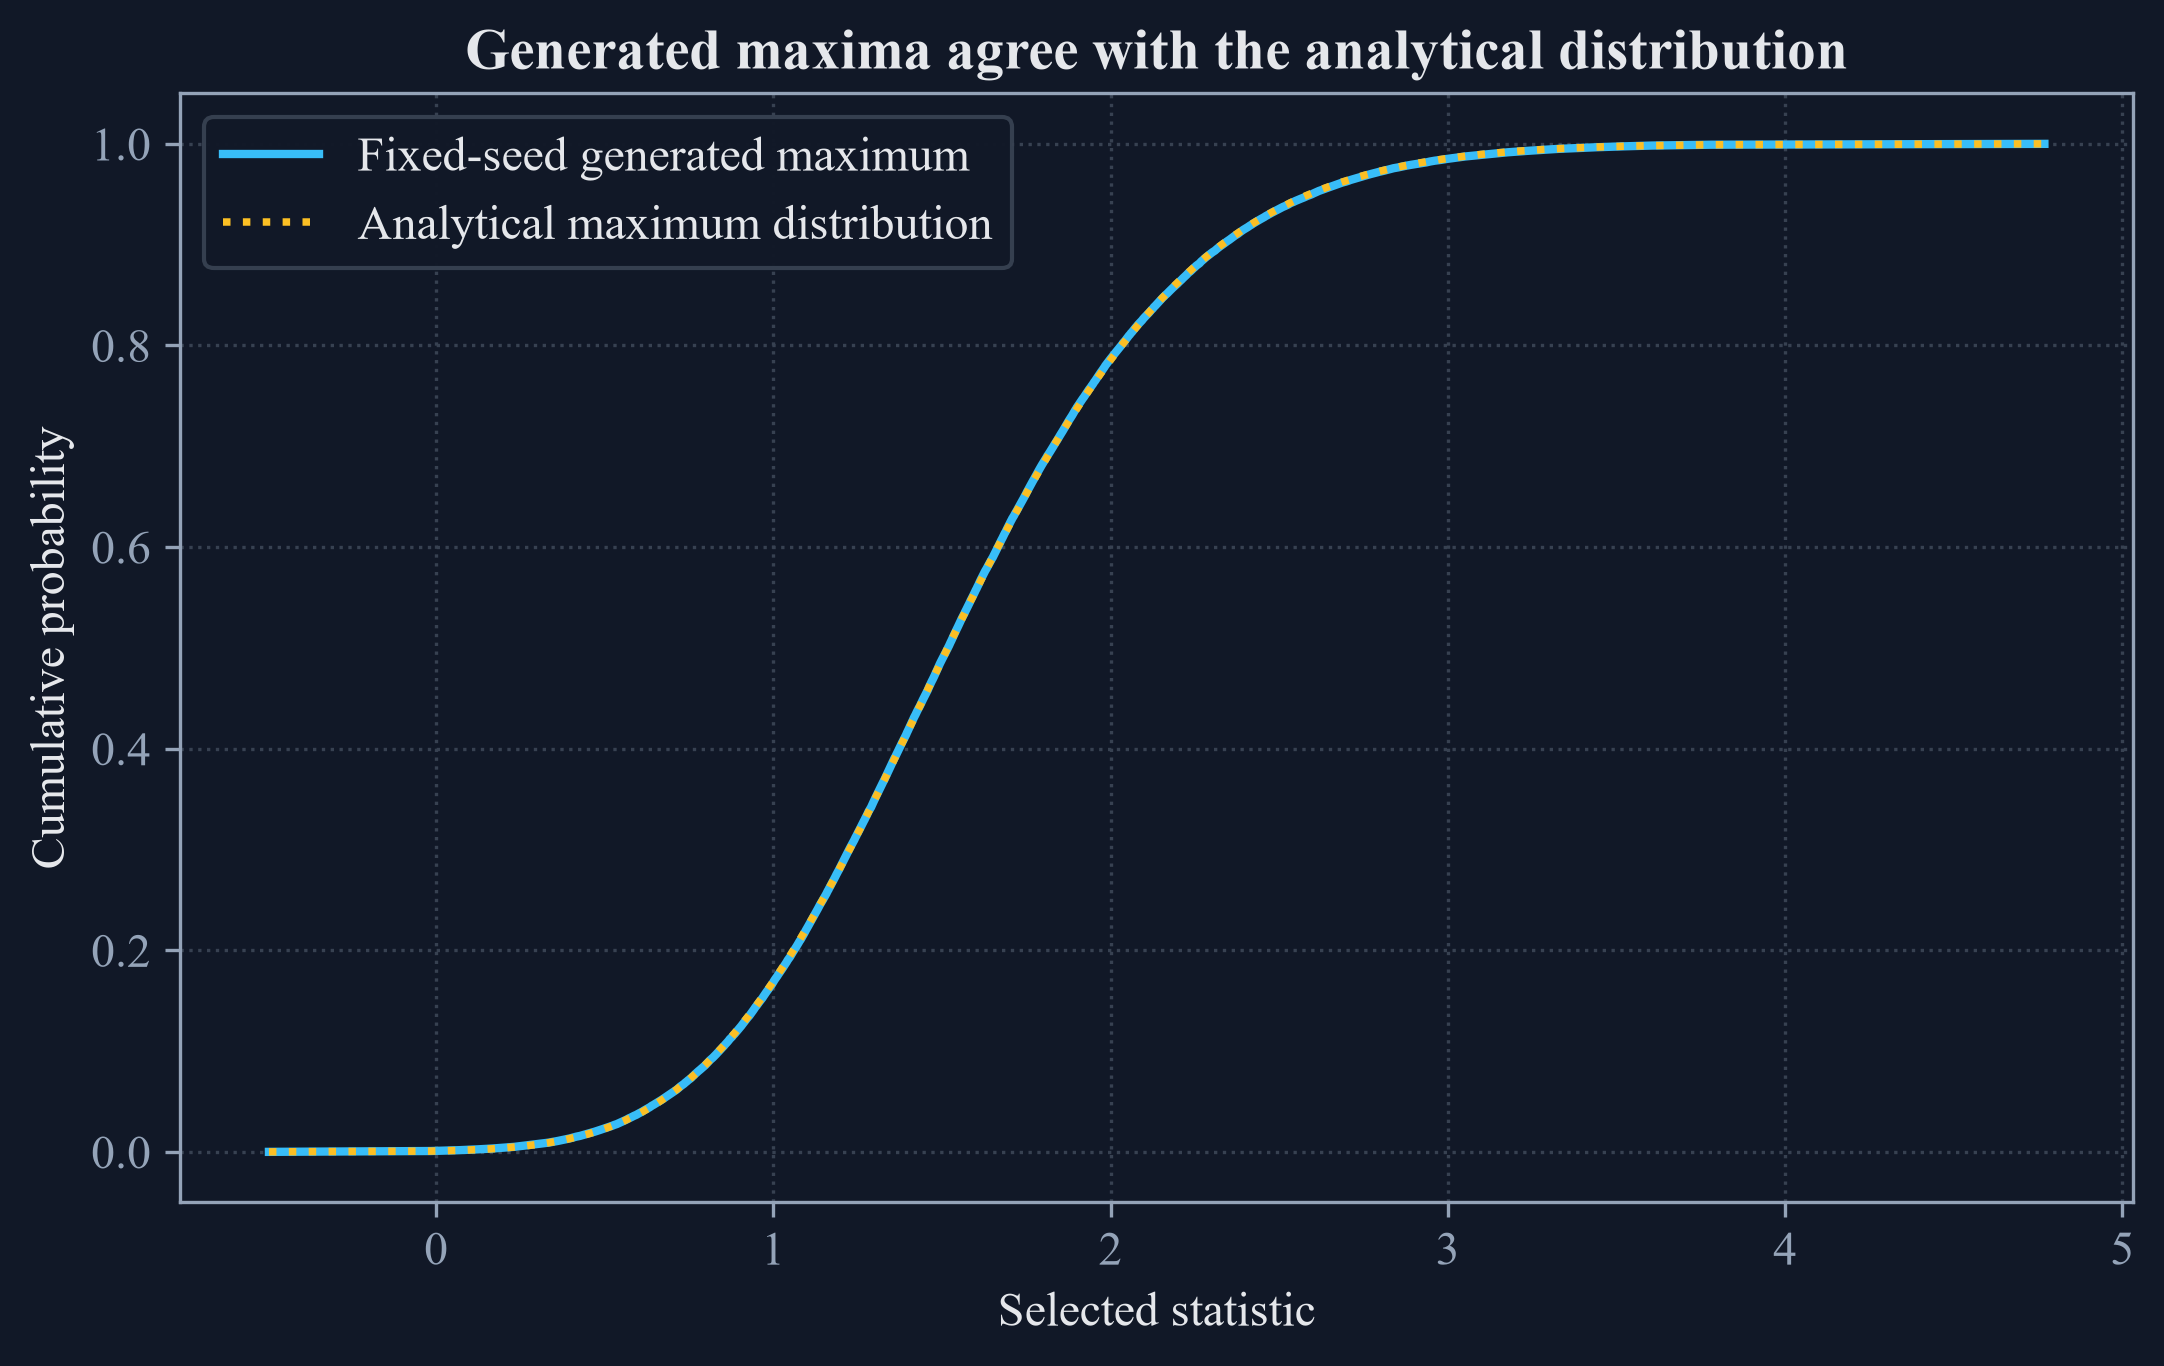

In [3]:
gaussian_model = GaussianTrialMixture(trial_null_probability=0.95, null_standard_deviation=1.0, alternative_mean=0.3, alternative_standard_deviation=1.0)
cdf_grid = np.linspace(-1.5, 4.0, 300)
figure, axis = plt.subplots(figsize=(8.6, 5.0))
for trials, color in zip([1, 5, 10, 20], [palette["muted"], palette["cyan"], palette["amber"], palette["rose"]]):
    values = [gaussian_max_selection_cdf(gaussian_model, value, trials) for value in cdf_grid]
    axis.plot(cdf_grid, values, color=color, linewidth=2.0, label=f"{trials} trials")
axis.set_xlabel("Selected statistic")
axis.set_ylabel("Cumulative probability")
axis.set_title("Distribution of the maximum of trial mixtures")
axis.legend()
axis.grid(True)
save_figure(figure, "fdr_maximum_cdf")

threshold_values = [1.64, 1.96, 2.33, 3.09]
threshold_rows = []
for threshold in threshold_values:
    alpha = float(norm.sf(threshold))
    beta = float(norm.cdf(threshold - gaussian_model.alternative_mean))
    errors = max_selection_family_errors(alpha, beta, gaussian_model.trial_null_probability, 10)
    family_fdr = family_level_false_discovery_rate(errors.family_type_i_error, errors.family_type_ii_error, gaussian_model.trial_null_probability, 10)
    threshold_rows.append({"Threshold": threshold, "Trial Type I error": alpha, "Trial Type II error": beta, "Family Type I error": errors.family_type_i_error, "Family Type II error": errors.family_type_ii_error, "Family false discovery rate": family_fdr})
threshold_table = pd.DataFrame(threshold_rows)
save_table(threshold_table, "fdr_threshold_grid", "Family error and false discovery calculations over reporting thresholds.", "tab:chapter27-fdr-threshold-grid")
display(threshold_table)

simulation_rng = np.random.default_rng(2703)
simulation_count = 100000
simulation_trials = 10
simulated_nulls = simulation_rng.random((simulation_count, simulation_trials)) < gaussian_model.trial_null_probability
simulated_values = simulation_rng.standard_normal((simulation_count, simulation_trials)) + np.where(simulated_nulls, 0.0, gaussian_model.alternative_mean)
simulated_maxima = simulated_values.max(axis=1)
simulation_thresholds = np.array([-0.5, 0.0, 1.0, 1.96, 3.0])
simulation_rows = []
for threshold in simulation_thresholds:
    analytical = gaussian_max_selection_cdf(gaussian_model, threshold, simulation_trials)
    empirical = float(np.mean(simulated_maxima <= threshold))
    standard_error = math.sqrt(analytical * (1.0 - analytical) / simulation_count)
    simulation_rows.append({"Threshold": threshold, "Analytical cumulative probability": analytical, "Generated cumulative probability": empirical, "Absolute difference": abs(empirical - analytical), "Two-standard-error allowance": 2.0 * standard_error})
simulation_table = pd.DataFrame(simulation_rows)
save_table(simulation_table, "fdr_simulation_check", "Fixed-seed check of the maximum-selection distribution.", "tab:chapter27-fdr-simulation")
display(simulation_table)

sorted_maxima = np.sort(simulated_maxima)
empirical_probabilities = np.arange(1, simulation_count + 1) / simulation_count
selected_points = np.linspace(0, simulation_count - 1, 1200, dtype=int)
analytical_curve = np.array([gaussian_max_selection_cdf(gaussian_model, value, simulation_trials) for value in sorted_maxima[selected_points]])
figure, axis = plt.subplots(figsize=(8.4, 4.8))
axis.plot(sorted_maxima[selected_points], empirical_probabilities[selected_points], color=palette["cyan"], linewidth=2.0, label="Fixed-seed generated maximum")
axis.plot(sorted_maxima[selected_points], analytical_curve, color=palette["amber"], linewidth=1.8, linestyle=":", label="Analytical maximum distribution")
axis.set_xlabel("Selected statistic")
axis.set_ylabel("Cumulative probability")
axis.set_title("Generated maxima agree with the analytical distribution")
axis.legend()
axis.grid(True)
save_figure(figure, "fdr_simulation_check")

## Comparing conditional tail risks

After selection above a threshold $c$, the upper-tail probability at $x\geq c$ is:

$$
\Pr(Z\geq x\mid Z\geq c)
=\frac{1-F_Z(x)}{1-F_Z(c)}.
$$

Here, $Z$ is the reported statistic under the distribution being examined, $F_Z$ is its cumulative distribution, $c$ is the selection threshold, and $x$ is a value at least as large as $c$.

,Case,Family Type I error,Equation log gap,Single-trial false discovery rate,Family false discovery rate,Equality holds,Single-trial value is an upper bound
0,Below equality,0.07875,-0.223144,0.2,0.166667,False,True
1,Equality,0.098437,0,0.2,0.2,True,True
2,Above equality,0.118125,0.182322,0.2,0.230769,False,False


,Trials,Selection threshold,Reported value,Conditional upper-tail probability
0,1,1.96,2,0.910971
1,1,1.96,2.5,0.251973
2,1,1.96,3,0.055625
3,1,1.96,3.5,0.009757
4,10,1.96,2,0.920361
5,10,1.96,2.5,0.274834
6,10,1.96,3,0.062086
7,10,1.96,3.5,0.01095
8,50,1.96,2,0.954112
9,50,1.96,2.5,0.383493


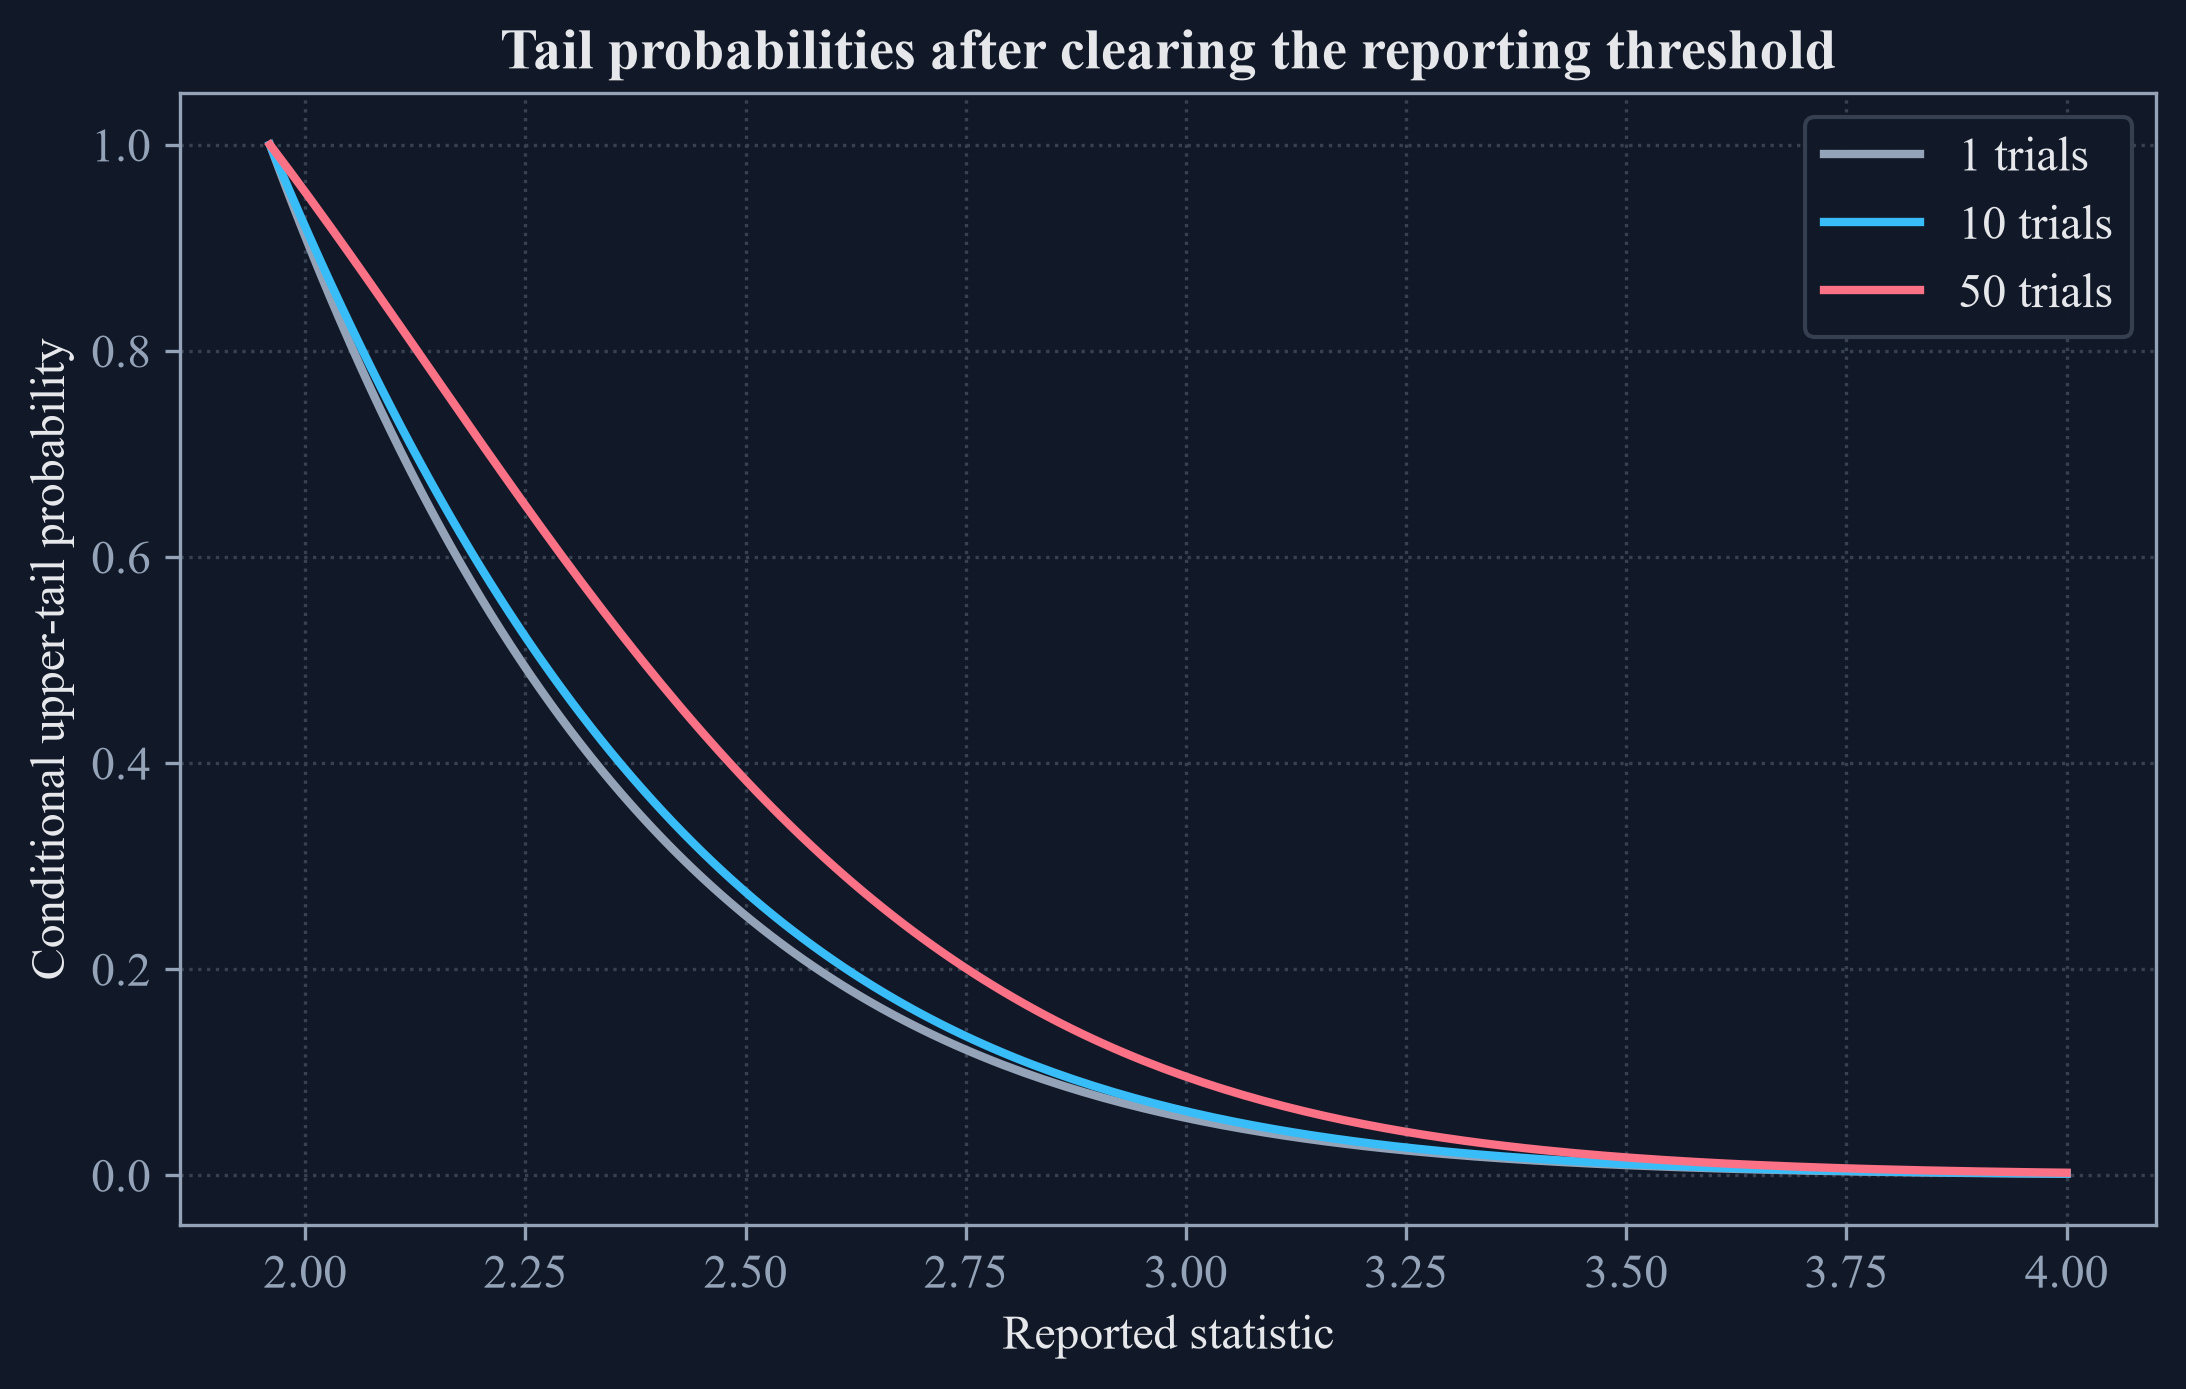

In [4]:
comparison_alpha = 0.05
comparison_beta = 0.20
comparison_prior = 0.80
comparison_trials = 2
comparison_family_beta = 0.30
required_ratio = (1.0 - comparison_family_beta) / (1.0 - comparison_beta) * (1.0 - comparison_prior ** comparison_trials) / (comparison_prior ** (comparison_trials - 1) * (1.0 - comparison_prior))
equality_alpha = comparison_alpha * required_ratio
comparison_rows = []
for name, family_alpha in [("Below equality", 0.8 * equality_alpha), ("Equality", equality_alpha), ("Above equality", 1.2 * equality_alpha)]:
    evidence = compare_single_and_family_fdr(comparison_alpha, comparison_beta, comparison_prior, comparison_trials, family_type_i_error=family_alpha, family_type_ii_error=comparison_family_beta)
    comparison_rows.append({"Case": name, "Family Type I error": family_alpha, "Equation log gap": evidence.equation_13_log_gap, "Single-trial false discovery rate": evidence.single_trial_false_discovery_rate, "Family false discovery rate": evidence.family_level_false_discovery_rate, "Equality holds": evidence.identification_condition_holds, "Single-trial value is an upper bound": evidence.single_trial_upper_bounds_family})
comparison_table = pd.DataFrame(comparison_rows)
save_table(comparison_table, "fdr_comparison_conditions", "Equality and inequality directions for one-trial and family false discovery rates.", "tab:chapter27-fdr-comparison")
display(comparison_table)

conditional_rows = []
selection_threshold = 1.96
for trials in [1, 10, 50]:
    cdf_at_threshold = gaussian_max_selection_cdf(gaussian_model, selection_threshold, trials)
    for value in [2.0, 2.5, 3.0, 3.5]:
        cdf_at_value = gaussian_max_selection_cdf(gaussian_model, value, trials)
        conditional_rows.append({"Trials": trials, "Selection threshold": selection_threshold, "Reported value": value, "Conditional upper-tail probability": conditional_upper_tail_probability(cdf_at_value, cdf_at_threshold)})
conditional_table = pd.DataFrame(conditional_rows)
save_table(conditional_table, "fdr_conditional_tail", "Conditional upper-tail probabilities after maximum selection.", "tab:chapter27-fdr-conditional-tail")
display(conditional_table)

conditional_grid = np.linspace(selection_threshold, 4.0, 180)
figure, axis = plt.subplots(figsize=(8.5, 4.9))
for trials, color in zip([1, 10, 50], [palette["muted"], palette["cyan"], palette["rose"]]):
    threshold_cdf = gaussian_max_selection_cdf(gaussian_model, selection_threshold, trials)
    tail_values = [conditional_upper_tail_probability(gaussian_max_selection_cdf(gaussian_model, value, trials), threshold_cdf) for value in conditional_grid]
    axis.plot(conditional_grid, tail_values, color=color, linewidth=2.0, label=f"{trials} trials")
axis.set_xlabel("Reported statistic")
axis.set_ylabel("Conditional upper-tail probability")
axis.set_title("Tail probabilities after clearing the reporting threshold")
axis.legend()
axis.grid(True)
save_figure(figure, "fdr_conditional_tail")

## Gaussian Calculations under Supplied Parameters

Under the supplied two-component Gaussian model, the one-trial mixture, selected-maximum density, and likelihood are:

$$
G(z)=\pi_0\Phi\!\left(\frac{z}{\sigma_0}\right)+(1-\pi_0)\Phi\!\left(\frac{z-\mu_1}{\sigma_1}\right),
\qquad
h_K(z)=K G(z)^{K-1}g(z),
\qquad
\ell=\sum_{i=1}^{n}\log h_K(z_i).
$$

Here, $\Phi$ is the standard-normal cumulative distribution, $\pi_0$ is the one-trial null probability, $\sigma_0$ is the null standard deviation, $\mu_1$ and $\sigma_1$ are the alternative mean and standard deviation, $G$ and $g$ are the mixture cumulative distribution and density, $h_K$ is the density of the maximum across $K$ trials, and $z_1,\ldots,z_n$ are supplied selected observations.

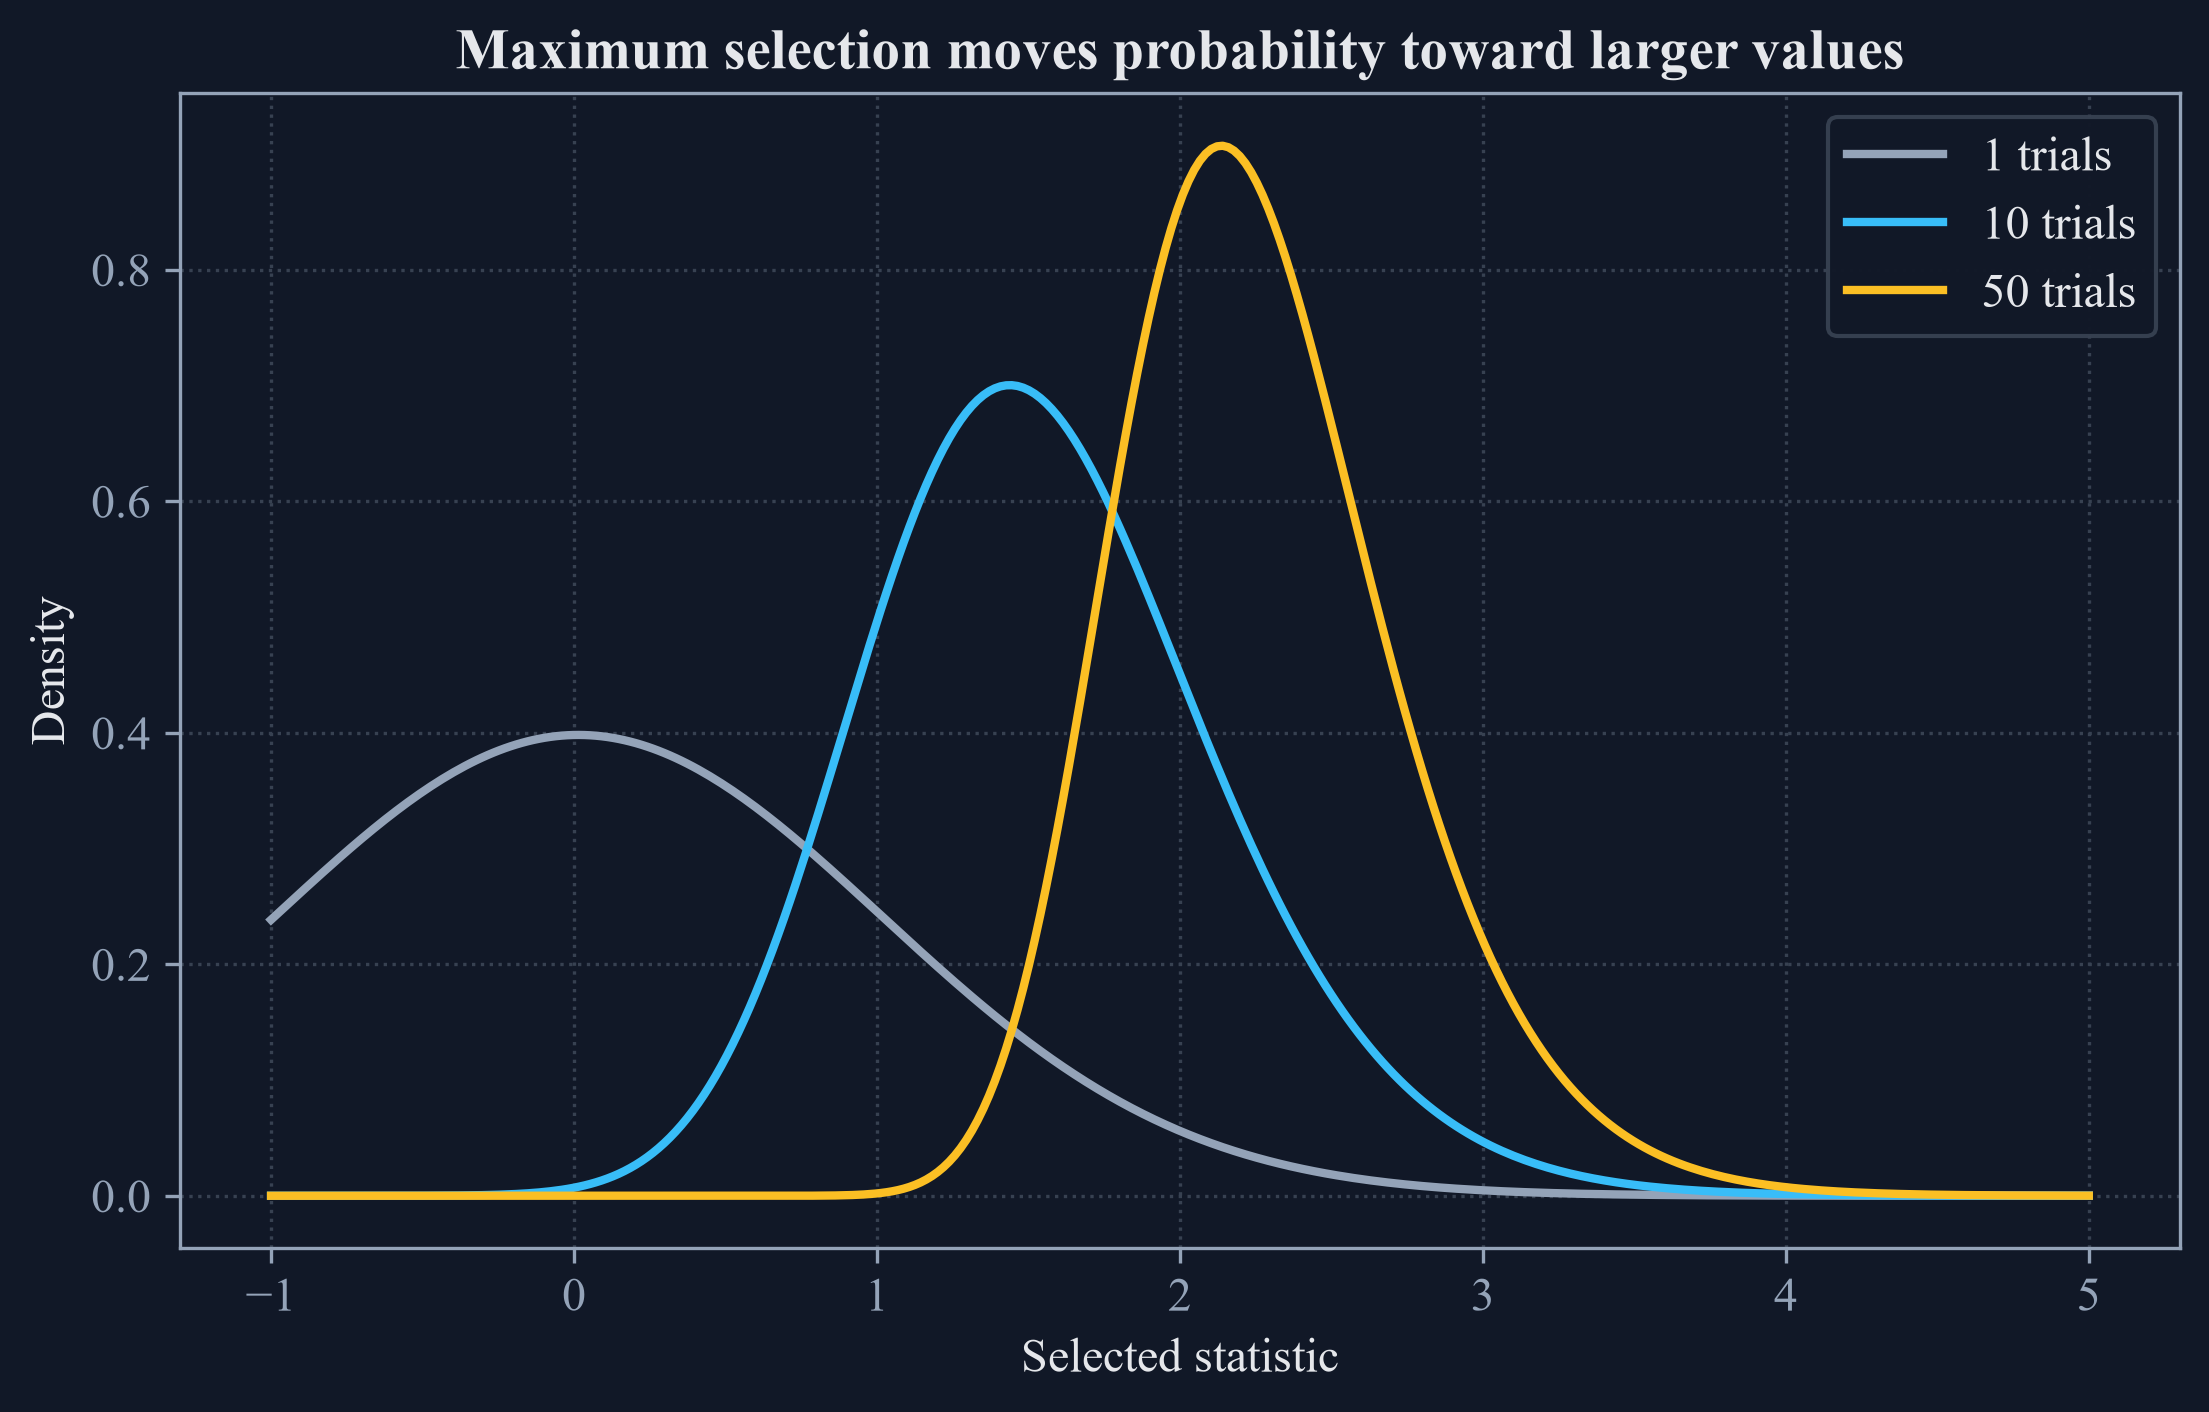

,Threshold,Trial Type I error,Trial Type II error,Family Type I error,Family Type II error
0,1.64,0.050503,0.909877,0.404423,0.564899
1,1.96,0.024998,0.951543,0.223654,0.753196
2,2.33,0.009903,0.978822,0.094732,0.892455


,Quantity,Value
0,Trials,10
1,Family null probability,0.598737
2,Mean family Type I error,0.240936
3,Mean family Type II error,0.73685
4,Search-adjusted family false discovery rate,0.577377


,Calculation,Value,Difference from returned likelihood
0,Sum of individual log densities,-12.381036,0
1,Returned log likelihood,-12.381036,0
2,Reversed observation order,-12.381036,0


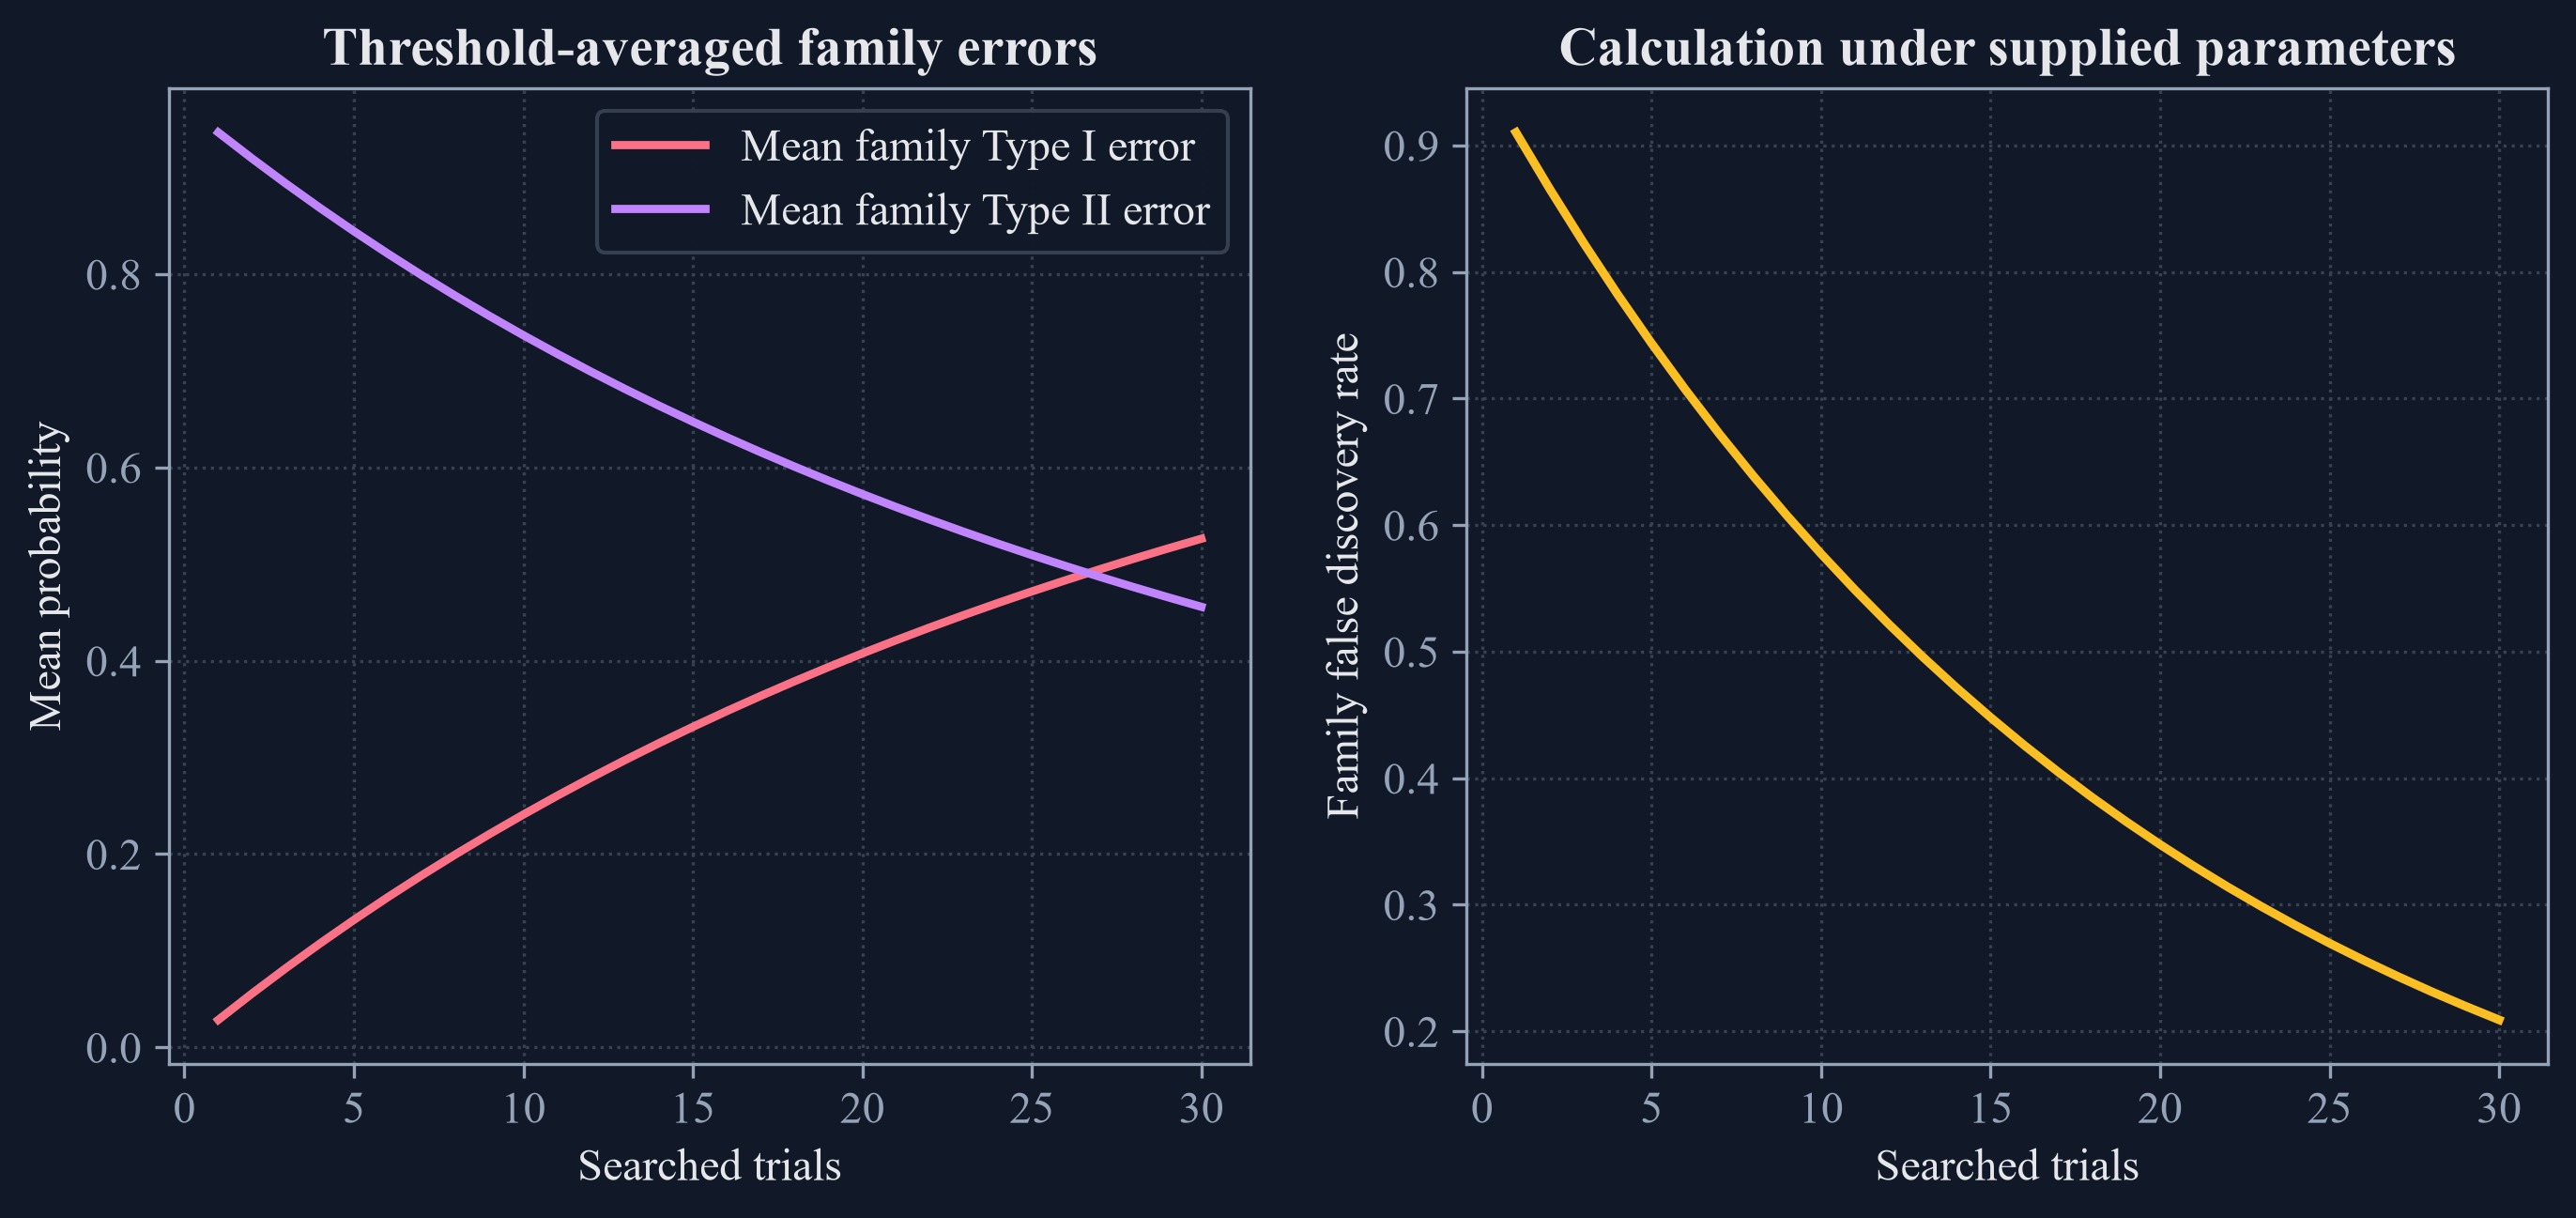

In [5]:
density_grid = np.linspace(-1.0, 5.0, 320)
figure, axis = plt.subplots(figsize=(8.6, 5.0))
for trials, color in zip([1, 10, 50], [palette["muted"], palette["cyan"], palette["amber"]]):
    densities = np.exp([gaussian_max_selection_log_density(gaussian_model, value, trials) for value in density_grid])
    axis.plot(density_grid, densities, color=color, linewidth=2.0, label=f"{trials} trials")
axis.set_xlabel("Selected statistic")
axis.set_ylabel("Density")
axis.set_title("Maximum selection moves probability toward larger values")
axis.legend()
axis.grid(True)
save_figure(figure, "fdr_gaussian_density")

supplied_thresholds = np.array([1.64, 1.96, 2.33])
gaussian_evidence = gaussian_search_adjusted_false_discovery_rate(gaussian_model, supplied_thresholds, 10)
gaussian_threshold_table = pd.DataFrame({"Threshold": gaussian_evidence.thresholds, "Trial Type I error": gaussian_evidence.trial_type_i_errors, "Trial Type II error": gaussian_evidence.trial_type_ii_errors, "Family Type I error": gaussian_evidence.family_type_i_errors, "Family Type II error": gaussian_evidence.family_type_ii_errors})
save_table(gaussian_threshold_table, "fdr_gaussian_thresholds", "Per-threshold Gaussian search-adjustment evidence under supplied parameters.", "tab:chapter27-fdr-gaussian-thresholds")
display(gaussian_threshold_table)

gaussian_aggregate = pd.DataFrame([
    {"Quantity": "Trials", "Value": gaussian_evidence.n_trials},
    {"Quantity": "Family null probability", "Value": gaussian_evidence.family_null_probability},
    {"Quantity": "Mean family Type I error", "Value": gaussian_evidence.mean_family_type_i_error},
    {"Quantity": "Mean family Type II error", "Value": gaussian_evidence.mean_family_type_ii_error},
    {"Quantity": "Search-adjusted family false discovery rate", "Value": gaussian_evidence.false_discovery_rate},
])
save_table(gaussian_aggregate, "fdr_gaussian_aggregate", "Aggregate Gaussian calculation under supplied parameters.", "tab:chapter27-fdr-gaussian-aggregate")
display(gaussian_aggregate)

likelihood_observations = simulated_maxima[:12]
direct_terms = np.array([gaussian_max_selection_log_density(gaussian_model, value, simulation_trials) for value in likelihood_observations])
likelihood_value = gaussian_max_selection_log_likelihood(gaussian_model, likelihood_observations, simulation_trials)
permuted_likelihood = gaussian_max_selection_log_likelihood(gaussian_model, likelihood_observations[::-1], simulation_trials)
likelihood_table = pd.DataFrame([
    {"Calculation": "Sum of individual log densities", "Value": direct_terms.sum(), "Difference from returned likelihood": abs(direct_terms.sum() - likelihood_value)},
    {"Calculation": "Returned log likelihood", "Value": likelihood_value, "Difference from returned likelihood": 0.0},
    {"Calculation": "Reversed observation order", "Value": permuted_likelihood, "Difference from returned likelihood": abs(permuted_likelihood - likelihood_value)},
])
save_table(likelihood_table, "fdr_likelihood_check", "Likelihood checks for supplied selected observations.", "tab:chapter27-fdr-likelihood")
display(likelihood_table)

calibration_rows = []
for trials in range(1, 31):
    evidence = gaussian_search_adjusted_false_discovery_rate(gaussian_model, supplied_thresholds, trials)
    calibration_rows.append({"Trials": trials, "Family null probability": evidence.family_null_probability, "Mean family Type I error": evidence.mean_family_type_i_error, "Mean family Type II error": evidence.mean_family_type_ii_error, "Family false discovery rate": evidence.false_discovery_rate})
calibration_frame = pd.DataFrame(calibration_rows)
figure, axes = plt.subplots(1, 2, figsize=(10.9, 4.5))
axes[0].plot(calibration_frame["Trials"], calibration_frame["Mean family Type I error"], color=palette["rose"], linewidth=2.1, label="Mean family Type I error")
axes[0].plot(calibration_frame["Trials"], calibration_frame["Mean family Type II error"], color=palette["violet"], linewidth=2.1, label="Mean family Type II error")
axes[0].set_xlabel("Searched trials")
axes[0].set_ylabel("Mean probability")
axes[0].set_title("Threshold-averaged family errors")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(calibration_frame["Trials"], calibration_frame["Family false discovery rate"], color=palette["amber"], linewidth=2.2)
axes[1].set_xlabel("Searched trials")
axes[1].set_ylabel("Family false discovery rate")
axes[1].set_title("Calculation under supplied parameters")
axes[1].grid(True)
save_figure(figure, "fdr_threshold_adjustment")

## Nonidentification from Selected Statistics Alone

A two-trial witness can preserve one observed cumulative probability while assigning any interior target family false discovery rate:

$$
\pi_0=\sqrt q,
\qquad
G(c)=\sqrt h,
\qquad
\alpha_F=1-h,
\qquad
\beta_F=h,
\qquad
\operatorname{FDR}_F=q.
$$

Here, $h$ is the observed cumulative probability of the selected statistic at threshold $c$, $q$ is any chosen family false discovery rate strictly between zero and one, $\pi_0$ is the constructed trial null probability, and $G(c)$ is a latent one-trial cumulative probability whose square reconstructs $h$.

,Target family false discovery rate,Constructed trial null probability,Latent trial cumulative probability,Reconstructed observed cumulative probability,Returned family false discovery rate
0,0.1,0.316228,0.8,0.64,0.1
1,0.3,0.547723,0.8,0.64,0.3
2,0.5,0.707107,0.8,0.64,0.5
3,0.8,0.894427,0.8,0.64,0.8
4,0.95,0.974679,0.8,0.64,0.95


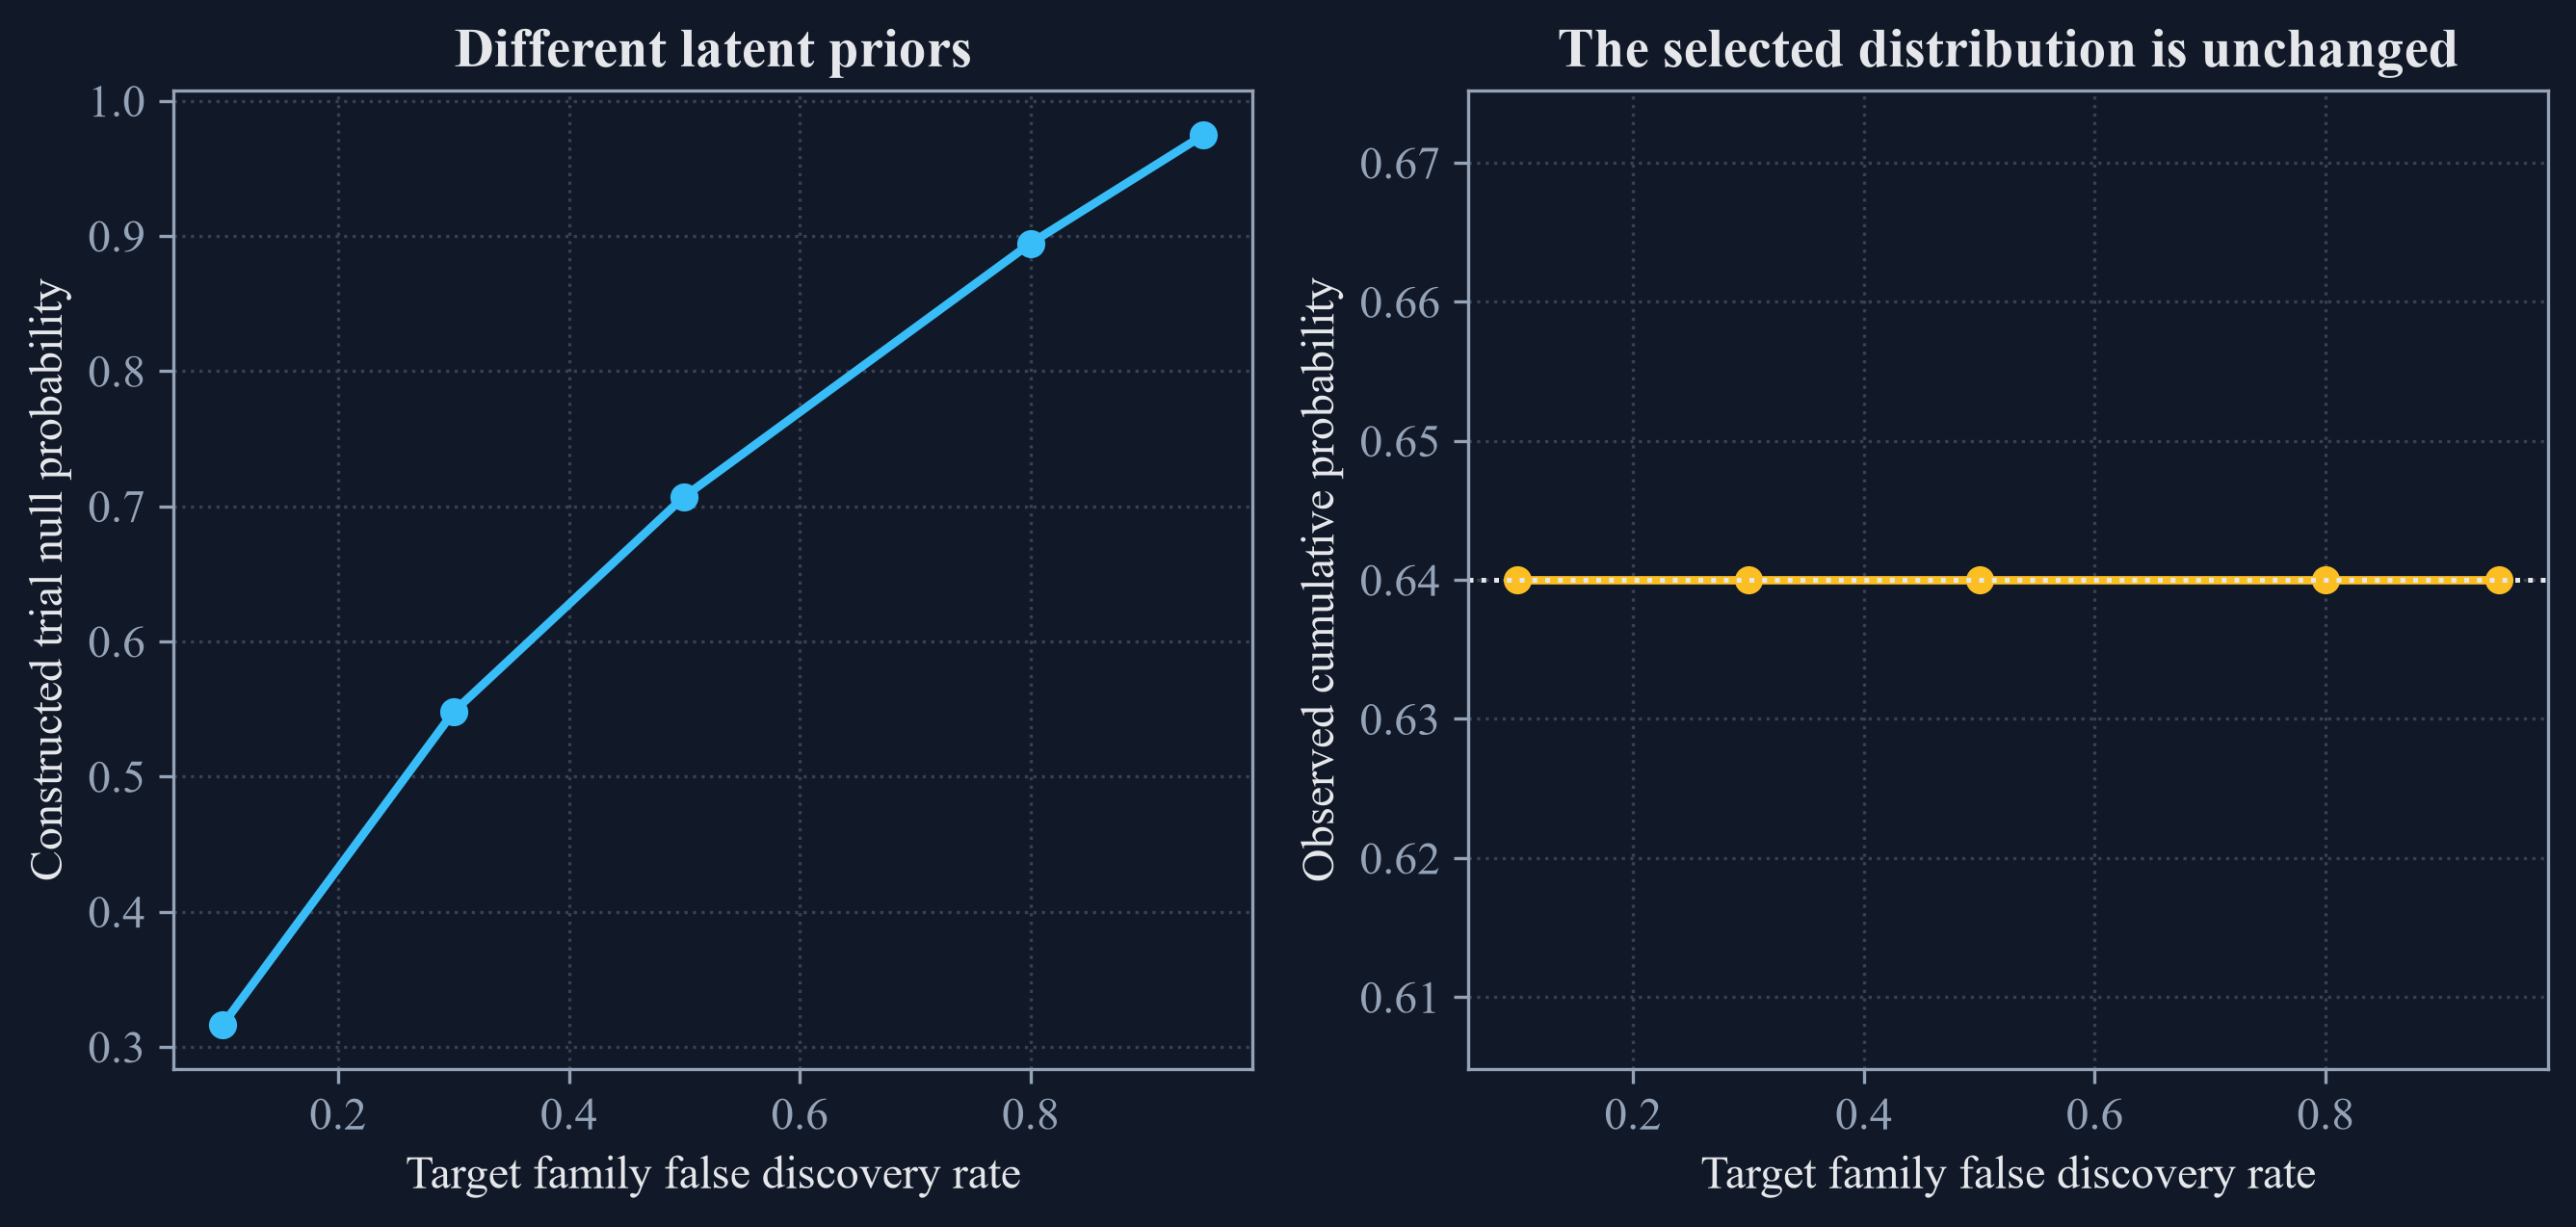

In [6]:
observable_cdf = 0.64
target_values = [0.10, 0.30, 0.50, 0.80, 0.95]
witness_rows = []
for target in target_values:
    witness = fdr_nonidentification_witness(observable_cdf, target)
    witness_rows.append({"Target family false discovery rate": witness.target_false_discovery_rate, "Constructed trial null probability": witness.trial_null_probability, "Latent trial cumulative probability": witness.latent_trial_cdf_at_threshold, "Reconstructed observed cumulative probability": witness.reconstructed_observable_cdf_at_threshold, "Returned family false discovery rate": witness.family_false_discovery_rate})
witness_table = pd.DataFrame(witness_rows)
save_table(witness_table, "fdr_nonidentification_witness", "Different false discovery rates that reconstruct the same selected cumulative probability.", "tab:chapter27-fdr-nonidentification")
display(witness_table)

figure, axes = plt.subplots(1, 2, figsize=(10.6, 4.4))
axes[0].plot(witness_table["Target family false discovery rate"], witness_table["Constructed trial null probability"], marker="o", color=palette["cyan"], linewidth=2.1)
axes[0].set_xlabel("Target family false discovery rate")
axes[0].set_ylabel("Constructed trial null probability")
axes[0].set_title("Different latent priors")
axes[0].grid(True)
axes[1].plot(witness_table["Target family false discovery rate"], witness_table["Reconstructed observed cumulative probability"], marker="o", color=palette["amber"], linewidth=2.1)
axes[1].axhline(observable_cdf, color=palette["text"], linestyle=":", linewidth=1.2)
axes[1].set_xlabel("Target family false discovery rate")
axes[1].set_ylabel("Observed cumulative probability")
axes[1].set_title("The selected distribution is unchanged")
axes[1].grid(True)
save_figure(figure, "fdr_nonidentification")

## The Selected Winner Has a Stricter Null Probability

The probability that the selected winner is null, conditional on clearing threshold $c$, is:

$$
\Pr(H_{I^{\star}}=0\mid Z_{(K)}>c)
=\frac{K\pi_0\int_c^{\infty}f_0(z)G(z)^{K-1}\,dz}{1-G(c)^K}.
$$

Here, $I^{\star}$ labels the trial attaining the maximum $Z_{(K)}$, $H_{I^{\star}}=0$ means that winning trial is null, $f_0$ is the null density, $G$ is the one-trial mixture cumulative distribution, $K$ is the search count, $\pi_0$ is the trial null probability, and $c$ is the reporting threshold.

,Trials,Family false discovery rate,Selected-winner null probability,Selection probability,Family minus selected-winner value,Quadrature absolute error
0,1,0.907421,0.907421,0.026171,0,0
1,5,0.740836,0.907172,0.124182,-0.166336,0
2,10,0.57486,0.906857,0.232943,-0.331996,0
3,20,0.346,0.906216,0.411624,-0.560216,0
4,50,0.075219,0.904251,0.734455,-0.829031,0


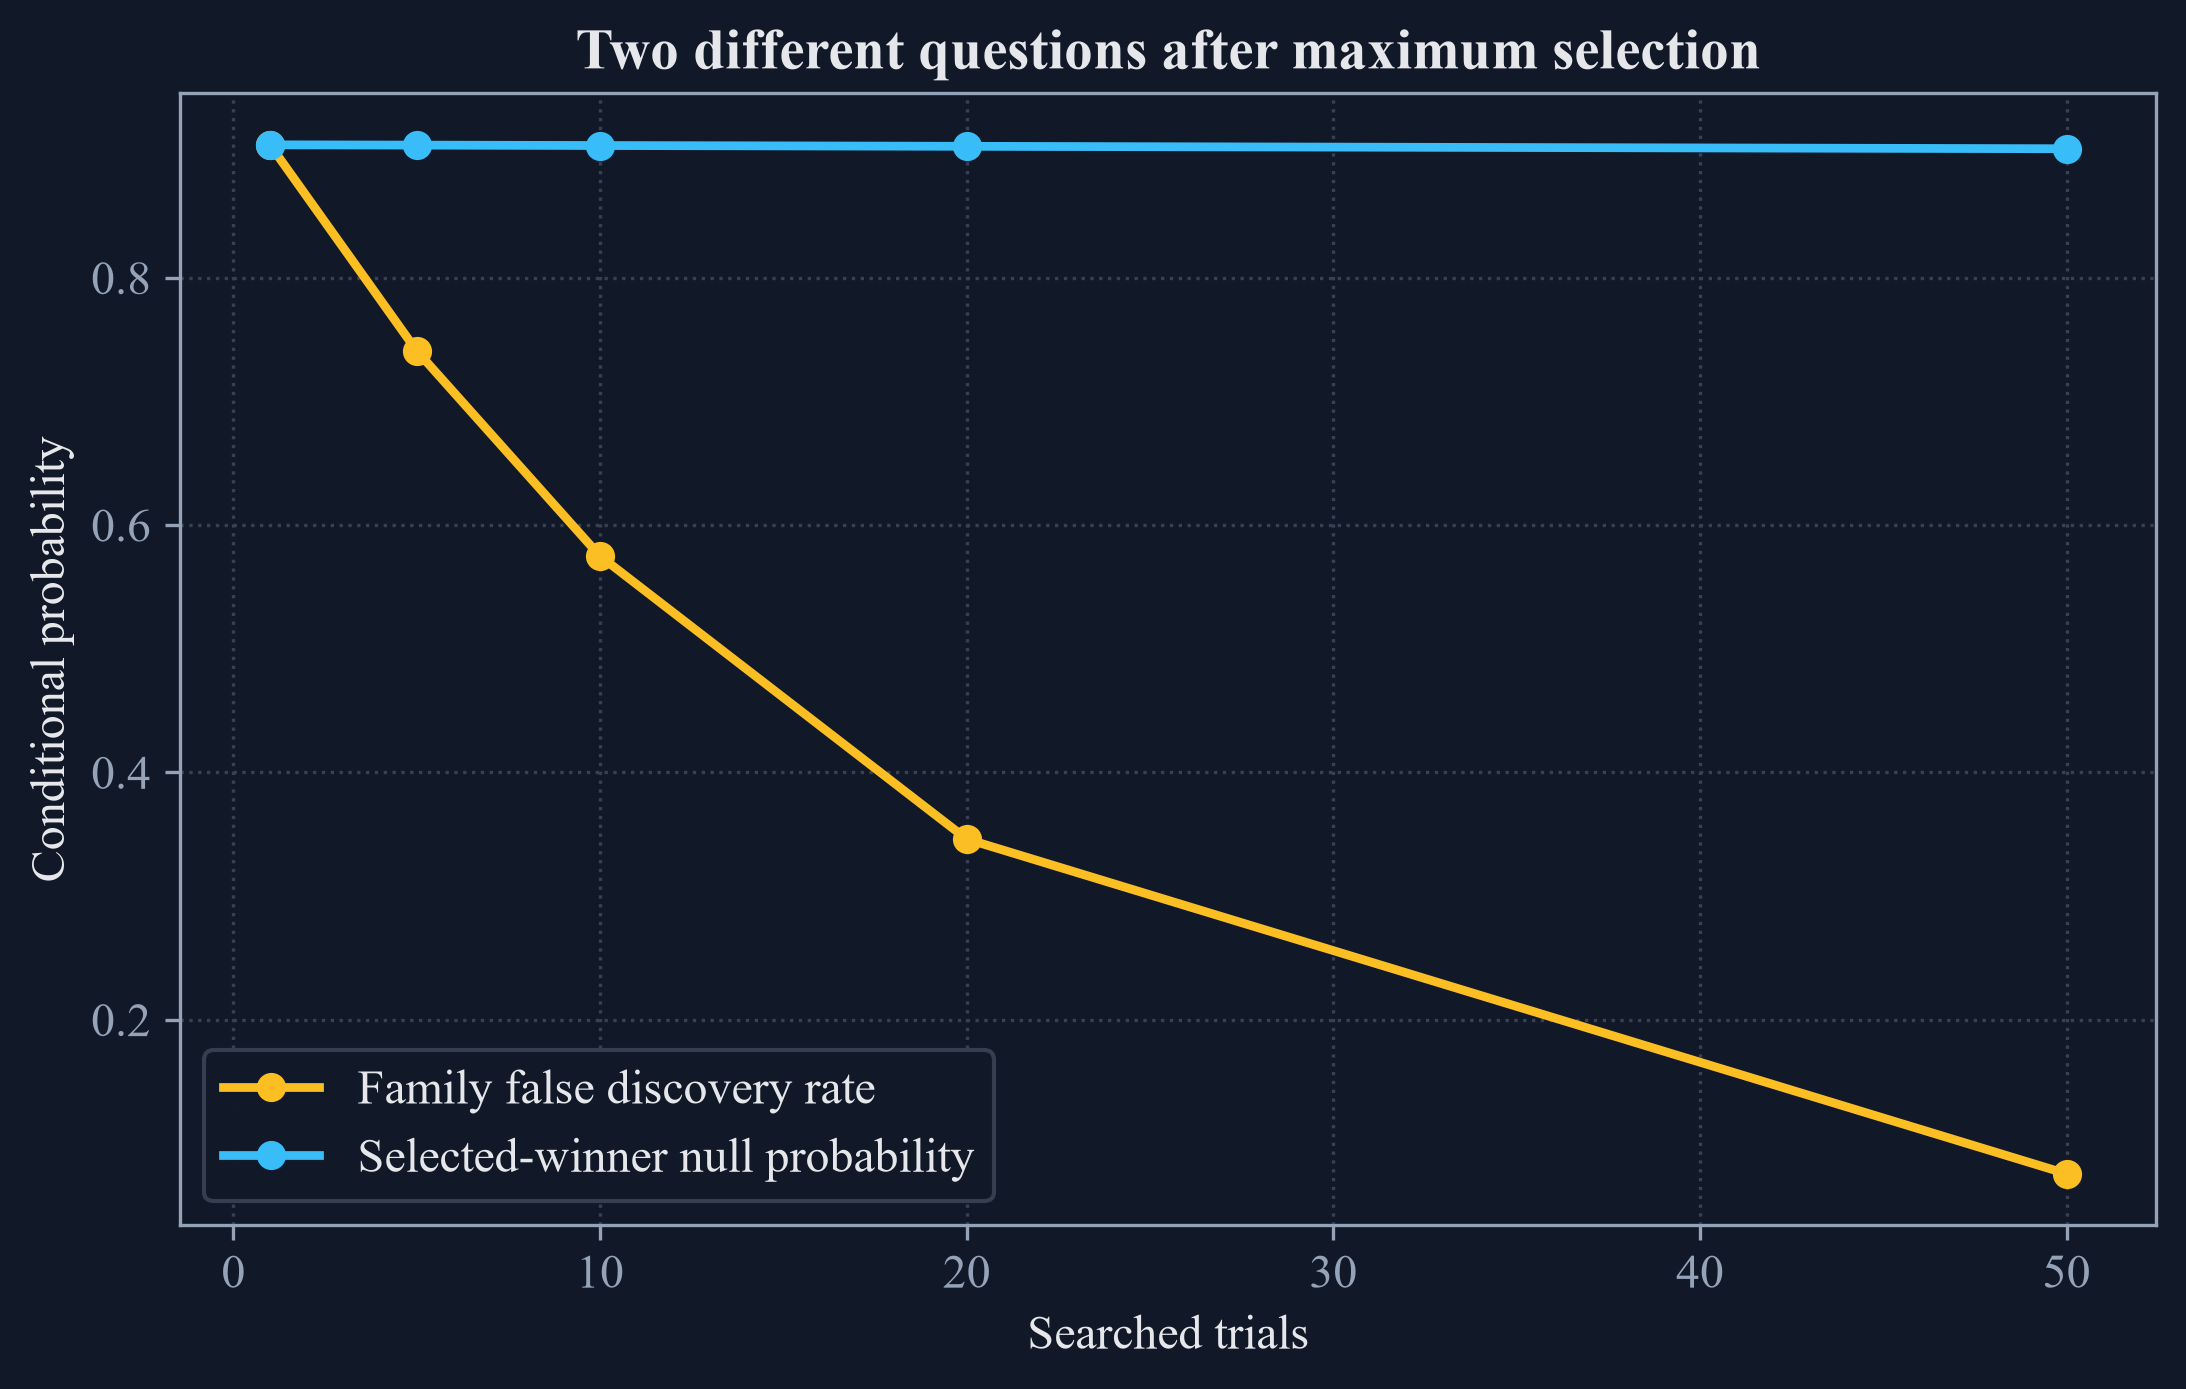

In [7]:
selected_threshold = 1.96
selected_rows = []
for trials in [1, 5, 10, 20, 50]:
    alpha = float(norm.sf(selected_threshold))
    beta = float(norm.cdf(selected_threshold - gaussian_model.alternative_mean))
    errors = max_selection_family_errors(alpha, beta, gaussian_model.trial_null_probability, trials)
    family_fdr = family_level_false_discovery_rate(errors.family_type_i_error, errors.family_type_ii_error, gaussian_model.trial_null_probability, trials)
    selected = max_selection_null_probability(selected_threshold, gaussian_model.trial_null_probability, trials, null_density=lambda value: normal_density(value, gaussian_model.null_standard_deviation), mixture_cdf=lambda value: gaussian_trial_mixture_cdf(gaussian_model, value))
    selected_rows.append({"Trials": trials, "Family false discovery rate": family_fdr, "Selected-winner null probability": selected.conditional_null_probability, "Selection probability": selected.selection_probability, "Family minus selected-winner value": family_fdr - selected.conditional_null_probability, "Quadrature absolute error": selected.quadrature_absolute_error})
selected_table = pd.DataFrame(selected_rows)
save_table(selected_table, "fdr_selection_level", "Family and selected-winner null probabilities under supplied Gaussian parameters.", "tab:chapter27-fdr-selection-level")
display(selected_table)

figure, axis = plt.subplots(figsize=(8.5, 4.9))
axis.plot(selected_table["Trials"], selected_table["Family false discovery rate"], marker="o", color=palette["amber"], linewidth=2.1, label="Family false discovery rate")
axis.plot(selected_table["Trials"], selected_table["Selected-winner null probability"], marker="o", color=palette["cyan"], linewidth=2.1, label="Selected-winner null probability")
axis.set_xlabel("Searched trials")
axis.set_ylabel("Conditional probability")
axis.set_title("Two different questions after maximum selection")
axis.legend()
axis.grid(True)
save_figure(figure, "fdr_family_vs_selection")

## Scope of the released calculations

In [8]:
input_checks = pd.DataFrame([
    contract_result("Probability below zero", lambda: single_trial_false_discovery_rate(-0.1, 0.2, 0.7), "ValueError"),
    contract_result("Zero trial count", lambda: max_selection_family_errors(0.05, 0.20, 0.70, 0), "ValueError"),
    contract_result("Undefined discovery posterior", lambda: single_trial_false_discovery_rate(0.0, 1.0, 0.5), "ValueError"),
    contract_result("Conditional cumulative values out of order", lambda: conditional_upper_tail_probability(0.2, 0.4), "ValueError"),
    contract_result("Zero Gaussian scale", lambda: GaussianTrialMixture(0.8, 0.0, 1.0, 1.0), "ValueError"),
    contract_result("Empty likelihood observations", lambda: gaussian_max_selection_log_likelihood(gaussian_model, [], 10), "ValueError"),
    contract_result("Boundary nonidentification target", lambda: fdr_nonidentification_witness(0.4, 0.0), "ValueError"),
    contract_result("Negative supplied null density", lambda: max_selection_null_probability(0.0, 0.5, 2, null_density=lambda value: -1.0, mixture_cdf=lambda value: 0.5), "ValueError"),
])
save_table(input_checks, "fdr_input_checks", "Rejected inputs at the public false discovery boundary.", "tab:chapter27-fdr-input")
display(input_checks)

record_rows = []
record_objects = [case_a_errors, compare_single_and_family_fdr(0.05, 0.2, 0.8, 2, family_type_i_error=equality_alpha, family_type_ii_error=0.3), gaussian_model, gaussian_evidence, fdr_nonidentification_witness(0.64, 0.3), max_selection_null_probability(1.96, 0.95, 2, null_density=lambda value: normal_density(value), mixture_cdf=lambda value: gaussian_trial_mixture_cdf(gaussian_model, value))]
for value in record_objects:
    try:
        first_field = fields(value)[0].name
        setattr(value, first_field, getattr(value, first_field))
        frozen = False
    except FrozenInstanceError:
        frozen = True
    array_fields = [getattr(value, field.name) for field in fields(value) if isinstance(getattr(value, field.name), np.ndarray)]
    arrays_read_only = all(not array.flags.writeable for array in array_fields)
    record_rows.append({"Result record": type(value).__name__, "Frozen": frozen, "Array fields read only": arrays_read_only, "Passed": frozen and arrays_read_only})
record_table = pd.DataFrame(record_rows)
save_table(record_table, "fdr_record_checks", "Immutability checks for returned false discovery evidence.", "tab:chapter27-fdr-record")
display(record_table)

public_surface = pd.DataFrame([
    {"Public group": "False discovery result records", "Count": 6, "Coverage": "Family errors, comparisons, Gaussian calculations, nonidentification, and selected-winner evidence"},
    {"Public group": "False discovery functions", "Count": 13, "Coverage": "One trial, searched families, maximum selection, Gaussian calculations, likelihood, and witness"},
    {"Public group": "Released false discovery checks", "Count": 42, "Coverage": "Identities, published cases, boundaries, oracles, numerical stability, and returned evidence"},
])
save_table(public_surface, "fdr_public_surface", "Released public search-adjustment material covered by Section 27.3.", "tab:chapter27-fdr-public-surface")
display(public_surface)

section_summary = pd.DataFrame([
    {"Quantity": "One-trial false discovery rate", "Question": "Was one reported trial null?", "Required information": "One-trial errors and one-trial null prior"},
    {"Quantity": "Family false discovery rate", "Question": "Was the entire searched family null?", "Required information": "Family errors, search count, and family null prior"},
    {"Quantity": "Selected-winner null probability", "Question": "Did the winning trial come from the null?", "Required information": "Null density, mixture distribution, threshold, and search count"},
    {"Quantity": "Gaussian supplied-parameter calculation", "Question": "What follows from a declared mixture?", "Required information": "Supplied mixture parameters and search count"},
])
save_table(section_summary, "fdr_section_summary", "The distinct questions answered by the Chapter 27 false discovery calculations.", "tab:chapter27-fdr-section-summary")
display(section_summary)

,Check,Expected result,Observed result,Passed
0,Probability below zero,ValueError,ValueError,True
1,Zero trial count,ValueError,ValueError,True
2,Undefined discovery posterior,ValueError,ValueError,True
3,Conditional cumulative values out of order,ValueError,ValueError,True
4,Zero Gaussian scale,ValueError,ValueError,True
5,Empty likelihood observations,ValueError,ValueError,True
6,Boundary nonidentification target,ValueError,ValueError,True
7,Negative supplied null density,ValueError,ValueError,True


,Result record,Frozen,Array fields read only,Passed
0,MaxSelectionFamilyErrors,True,True,True
1,FDRComparisonEvidence,True,True,True
2,GaussianTrialMixture,True,True,True
3,GaussianSearchAdjustedFDR,True,True,True
4,FDRNonIdentificationWitness,True,True,True
5,SelectionLevelProbabilityEvidence,True,True,True


,Public group,Count,Coverage
0,False discovery result records,6,"Family errors, comparisons, Gaussian calculati..."
1,False discovery functions,13,"One trial, searched families, maximum selectio..."
2,Released false discovery checks,42,"Identities, published cases, boundaries, oracl..."


,Quantity,Question,Required information
0,One-trial false discovery rate,Was one reported trial null?,One-trial errors and one-trial null prior
1,Family false discovery rate,Was the entire searched family null?,"Family errors, search count, and family null p..."
2,Selected-winner null probability,Did the winning trial come from the null?,"Null density, mixture distribution, threshold,..."
3,Gaussian supplied-parameter calculation,What follows from a declared mixture?,Supplied mixture parameters and search count


## Tests

In [9]:
assert np.isclose(case_b_fdr, 0.08344067427559432, rtol=2e-15)
assert np.isclose(case_a_errors.family_type_i_error, 0.22365361940347483, rtol=2e-15)
assert np.isclose(case_a_errors.family_type_ii_error, 0.7531960884251256, rtol=2e-15)
assert np.isclose(case_a_errors.family_null_probability, 0.5987369392383787, rtol=2e-15)
assert np.isclose(case_a_fdr, 0.5748603608683863, rtol=2e-15)
assert (simulation_table["Absolute difference"] <= simulation_table["Two-standard-error allowance"] + 0.0015).all()
assert comparison_table.loc[comparison_table["Case"] == "Equality", "Equality holds"].iloc[0]
assert np.isclose(likelihood_value, direct_terms.sum(), rtol=1e-14, atol=1e-14)
assert np.isclose(likelihood_value, permuted_likelihood, rtol=1e-14, atol=1e-14)
np.testing.assert_allclose(witness_table["Reconstructed observed cumulative probability"], observable_cdf, atol=2e-15)
np.testing.assert_allclose(witness_table["Returned family false discovery rate"], witness_table["Target family false discovery rate"], atol=2e-15)
assert selected_table["Family false discovery rate"].between(0.0, 1.0).all()
assert selected_table["Selected-winner null probability"].between(0.0, 1.0).all()
assert selected_table["Selection probability"].between(0.0, 1.0).all()
np.testing.assert_allclose(selected_table["Family minus selected-winner value"], selected_table["Family false discovery rate"] - selected_table["Selected-winner null probability"], atol=2e-15)
assert selected_table["Quadrature absolute error"].max() < 3e-10
assert np.isclose(selected_table.loc[selected_table["Trials"] == 1, "Family false discovery rate"].iloc[0], selected_table.loc[selected_table["Trials"] == 1, "Selected-winner null probability"].iloc[0], atol=1e-11)
assert input_checks["Passed"].all()
assert record_table["Passed"].all()
assert public_surface["Count"].sum() == 61
assert isinstance(case_a_errors, MaxSelectionFamilyErrors)
assert isinstance(gaussian_evidence, GaussianSearchAdjustedFDR)
for stem in ["fdr_search_count_paths", "fdr_maximum_cdf", "fdr_simulation_check", "fdr_conditional_tail", "fdr_gaussian_density", "fdr_threshold_adjustment", "fdr_nonidentification", "fdr_family_vs_selection"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["fdr_single_trial_bayes", "fdr_single_trial_boundaries", "fdr_published_cases", "fdr_search_count_grid", "fdr_threshold_grid", "fdr_simulation_check", "fdr_comparison_conditions", "fdr_conditional_tail", "fdr_gaussian_thresholds", "fdr_gaussian_aggregate", "fdr_likelihood_check", "fdr_nonidentification_witness", "fdr_selection_level", "fdr_input_checks", "fdr_record_checks", "fdr_public_surface", "fdr_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()